# ECSE 551 — Assignment 1
**Jocelyn Poon, Maxime Robatche-Claive, Louis Salanon and Ruiyong Xu**

This notebook contains Tasks 1 and 2 for Diabetes regression and Digits classification,
followed by Task 3 on next-day stock returns. Run the cells in order with **Python 3.12+**.
Dependencies: NumPy, pandas, SciPy, scikit-learn, Matplotlib, seaborn and IPython.
Task 3 reads the supplied CSVs from the one editable `DATA_DIR` setting below.


# Tasks 1 and 2 — Diabetes regression
## Task 1: data analysis


In [3]:
from sklearn.datasets import load_diabetes
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

FIG_WIDTH = 8        

# Load the data twice: in original units, and with scikit-learn's default scaling (centred and scaled)
raw = load_diabetes(scaled=False, as_frame=True)
diabetes = load_diabetes()
featurenames = list(diabetes.feature_names)
df_raw = raw.frame.copy()
df_scaled = pd.DataFrame(diabetes.data, columns=featurenames)
df_scaled["target"] = diabetes.target

# Data checks: missing, non-finite and duplicated values, and the expected columns
print(f"Features: {featurenames}")
print(f"Shape: {df_raw.shape}")
print(f"Missing values: {int(df_raw.isnull().sum().sum())} | non-finite values: {int((~np.isfinite(df_raw)).sum().sum())}"
      f" | duplicate rows: {int(df_raw.duplicated().sum())}")
assert set(featurenames) <= set(df_raw.columns), "missing feature columns"
df_raw = df_raw.replace([np.inf, -np.inf], np.nan).dropna().drop_duplicates()
df_scaled = df_scaled.loc[df_raw.index]
print(f"Shape after cleaning: {df_raw.shape} (nothing had to be removed)")

# Plot helpers shared by the unscaled and the scaled analysis
def plot_distributions(frame, title):
    frame[featurenames].hist(bins=20, figsize=(FIG_WIDTH, 6), edgecolor="black")
    fig = plt.gcf()
    fig.suptitle(title)
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()

def plot_boxplots(frame, title):
    fig, axes = plt.subplots(2, 5, figsize=(FIG_WIDTH, 4.5))
    for ax, feature in zip(axes.flat, featurenames):
        ax.boxplot(frame[feature].dropna())
        ax.set_title(feature)
        ax.set_xticks([])
        ax.set_ylabel("Value")
    fig.suptitle(title)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    plt.show()

def plot_scatters(frame, title):
    pairs = [("bmi", "bp", "BMI", "Blood pressure", "BMI vs Blood Pressure"),
             ("bmi", "target", "BMI", "Disease progression", "BMI vs Target"),
             ("s5", "target", "s5", "Disease progression", "s5 vs Target"),
             ("s2", "s1", "s2", "s1", "s2 vs s1")]
    fig, axes = plt.subplots(1, 4, figsize=(FIG_WIDTH, 3.0))
    for ax, (x, y, xlabel, ylabel, subtitle) in zip(axes, pairs):
        ax.scatter(frame[x], frame[y], alpha=0.5, s=8)
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
        ax.set_title(subtitle, fontsize=8)
    fig.suptitle(title)
    fig.tight_layout(rect=(0, 0, 1, 0.93))
    plt.show()

print("\nOriginal units: summary statistics of each feature")
display(df_raw[featurenames].describe().T.round(3))

Features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Shape: (442, 11)
Missing values: 0 | non-finite values: 0 | duplicate rows: 0
Shape after cleaning: (442, 11) (nothing had to be removed)

Original units: summary statistics of each feature


,count,mean,std,min,25%,50%,75%,max
age,442.0,48.518,13.109,19.000,38.250,50.00,59.000,79.000
sex,442.0,1.468,0.500,1.000,1.000,1.00,2.000,2.000
bmi,442.0,26.376,4.418,18.000,23.200,25.70,29.275,42.200
bp,442.0,94.647,13.831,62.000,84.000,93.00,105.000,133.000
s1,442.0,189.140,34.608,97.000,164.250,186.00,209.750,301.000
s2,442.0,115.439,30.413,41.600,96.050,113.00,134.500,242.400
s3,442.0,49.788,12.934,22.000,40.250,48.00,57.750,99.000
s4,442.0,4.070,1.290,2.000,3.000,4.00,5.000,9.090
s5,442.0,4.641,0.522,3.258,4.277,4.62,4.997,6.107
s6,442.0,91.260,11.496,58.000,83.250,91.00,98.000,124.000


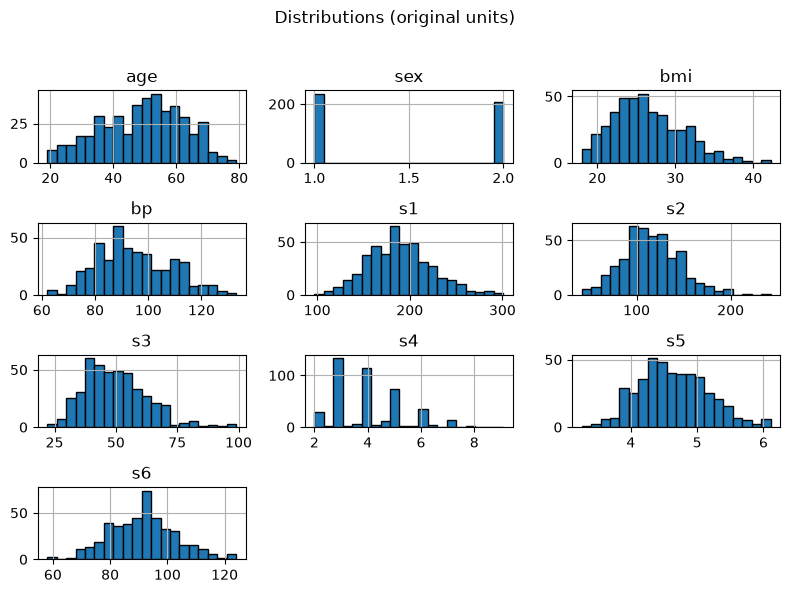

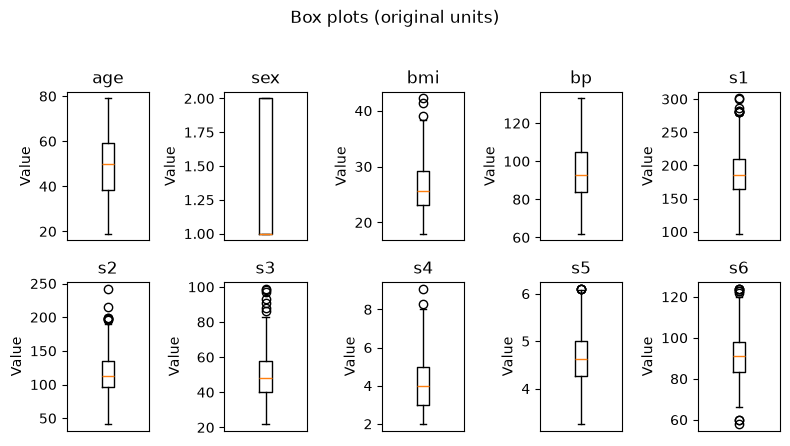

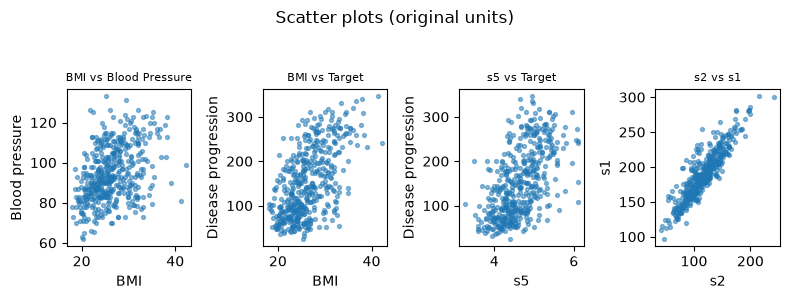

In [2]:
plot_distributions(df_raw, "Distributions (original units)")
plot_boxplots(df_raw, "Box plots (original units)")
plot_scatters(df_raw, "Scatter plots (original units)")

Scaled features (scikit-learn default scaling): summary statistics of each feature


,count,mean,std,min,25%,50%,75%,max
age,442.0,-0.0,0.048,-0.107,-0.037,0.005,0.038,0.111
sex,442.0,0.0,0.048,-0.045,-0.045,-0.045,0.051,0.051
bmi,442.0,-0.0,0.048,-0.090,-0.034,-0.007,0.031,0.171
bp,442.0,-0.0,0.048,-0.112,-0.037,-0.006,0.036,0.132
s1,442.0,-0.0,0.048,-0.127,-0.034,-0.004,0.028,0.154
s2,442.0,0.0,0.048,-0.116,-0.030,-0.004,0.030,0.199
s3,442.0,-0.0,0.048,-0.102,-0.035,-0.007,0.029,0.181
s4,442.0,-0.0,0.048,-0.076,-0.039,-0.003,0.034,0.185
s5,442.0,0.0,0.048,-0.126,-0.033,-0.002,0.032,0.134
s6,442.0,0.0,0.048,-0.138,-0.033,-0.001,0.028,0.136


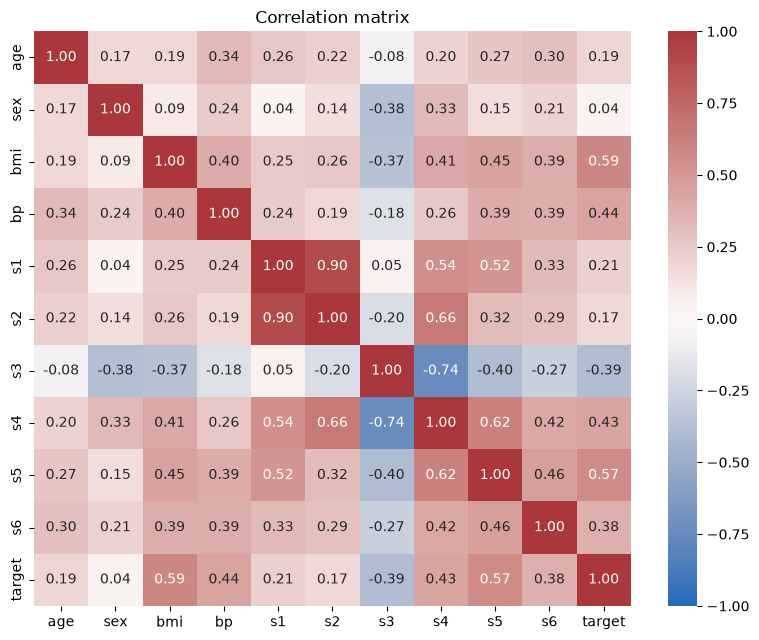

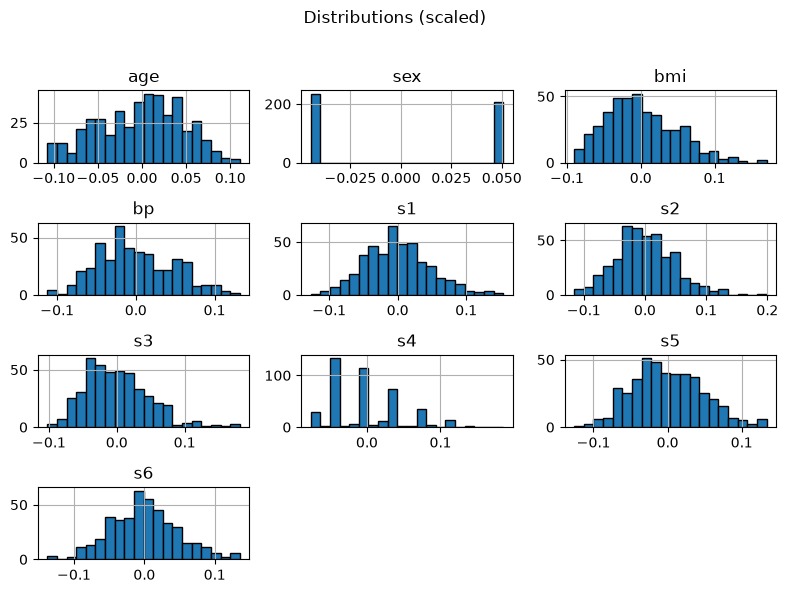

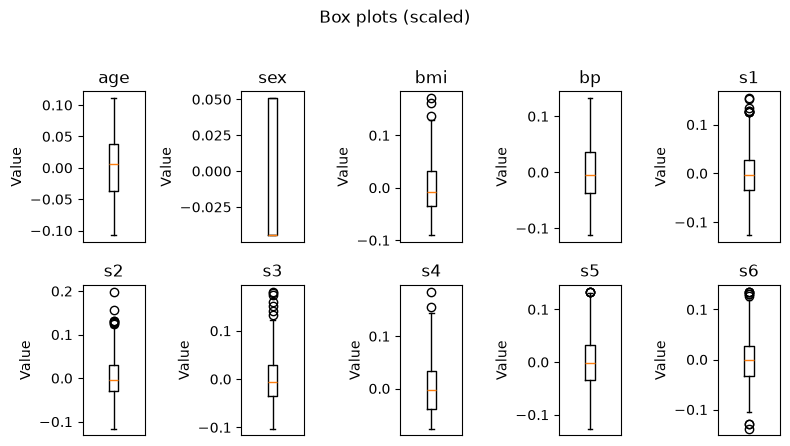

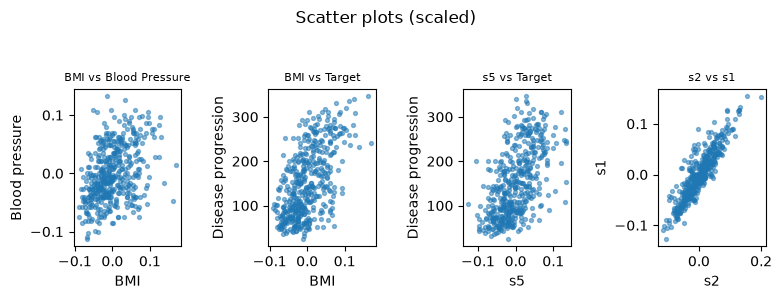

In [3]:
print("Scaled features (scikit-learn default scaling): summary statistics of each feature")
display(df_scaled[featurenames].describe().T.round(3))

fig, ax = plt.subplots(figsize=(FIG_WIDTH, 6.5))
sns.heatmap(df_scaled.corr(), annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation matrix")
fig.tight_layout()
plt.show()

plot_distributions(df_scaled, "Distributions (scaled)")
plot_boxplots(df_scaled, "Box plots (scaled)")
plot_scatters(df_scaled, "Scatter plots (scaled)")

## Task 2: ElasticNet regression
The existing implementation, comparison and parameter experiments are retained unchanged.


In [18]:
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import seaborn as sns

class ElasticNetRegression():

    def __init__(self, learning_rate, iterations, l1_penalty, l2_penalty):
        self.learning_rate = learning_rate
        self.iterations = iterations
        self.l1_penalty = l1_penalty
        self.l2_penalty = l2_penalty
        self.W = None
        self.b = None

    def fit(self, X, Y):
        self.m, self.n = X.shape
        self.W = np.zeros(self.n)
        self.b = 0.0
        self.X = X
        self.Y = Y
        self.loss_history = []
        for _ in range(self.iterations):
            self.update_weights()
        return self

    def update_weights(self):
        Y_prediction = self.predict(self.X)

        #gradients
        grad_W = (self.X.T @ (Y_prediction - self.Y) / self.m + self.l1_penalty * np.sign(self.W) + self.l2_penalty * self.W)
        grad_b = np.mean(Y_prediction - self.Y)

        #gradient descent
        self.W -= self.learning_rate * grad_W
        self.b -= self.learning_rate * grad_b

        # calculate objective function
        residuals = self.Y - self.predict(self.X)
        mse_loss = np.sum(residuals ** 2) / (2 * self.m)
        l1_loss = self.l1_penalty * np.sum(np.abs(self.W))
        l2_loss = 0.5 * self.l2_penalty * np.sum(self.W ** 2)
        self.loss_history.append(mse_loss + l1_loss + l2_loss)

    def predict(self, X):
        return X @ self.W + self.b


In [21]:
X, y = load_diabetes(return_X_y=True)
feature_names = load_diabetes().feature_names
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
X_sc = StandardScaler()
X_train_sc = X_sc.fit_transform(X_train)
X_test_sc = X_sc.transform(X_test)
y_sc = StandardScaler()
y_train_sc = y_sc.fit_transform(y_train.reshape(-1, 1)).ravel()

alpha = 0.05
l1_ratio = 0.5

l1_penalty = alpha*l1_ratio
l2_penalty = alpha*(1-l1_ratio)

mymodel = ElasticNetRegression(
    learning_rate=0.05,
    iterations=10000,
    l1_penalty=l1_penalty,
    l2_penalty=l2_penalty
)

mymodel.fit(X_train_sc, y_train_sc)
mymodel_n_iter = len(mymodel.loss_history)

sklearn_model = LinearRegression()

sklearn_model.fit(X_train_sc, y_train_sc)

scratch_scaled_preds = mymodel.predict(X_test_sc)
sklearn_scaled_preds = sklearn_model.predict(X_test_sc)

#unstandardize
scratch_preds = y_sc.inverse_transform(scratch_scaled_preds.reshape(-1, 1)).ravel()
sklearn_preds = y_sc.inverse_transform(sklearn_scaled_preds.reshape(-1, 1)).ravel()

def evaluate(name, y_true, predictions):
    print(f"{name}: test MSE {mean_squared_error(y_true, predictions):.2f}, R2 {r2_score(y_true, predictions):.4f}")


evaluate("Elastic Net", y_test, scratch_preds)
evaluate("Scikit Learn LinearRegression", y_test, sklearn_preds)

print(f"Custom iterations: {mymodel_n_iter}")
print("Standardized coefficients:")
display(pd.DataFrame({"Elastic Net": mymodel.W, "LinearRegression": sklearn_model.coef_}, index=feature_names).round(3))


Elastic Net: test MSE 2773.64, R2 0.4862
Scikit Learn LinearRegression: test MSE 2821.75, R2 0.4773
Custom iterations: 10000
Standardized coefficients:


,Elastic Net,LinearRegression
age,0.002,0.017
sex,-0.104,-0.159
bmi,0.335,0.334
bp,0.205,0.237
s1,-0.034,-0.552
s2,-0.001,0.309
s3,-0.166,0.073
s4,0.000,0.178
s5,0.224,0.403
s6,0.021,0.025


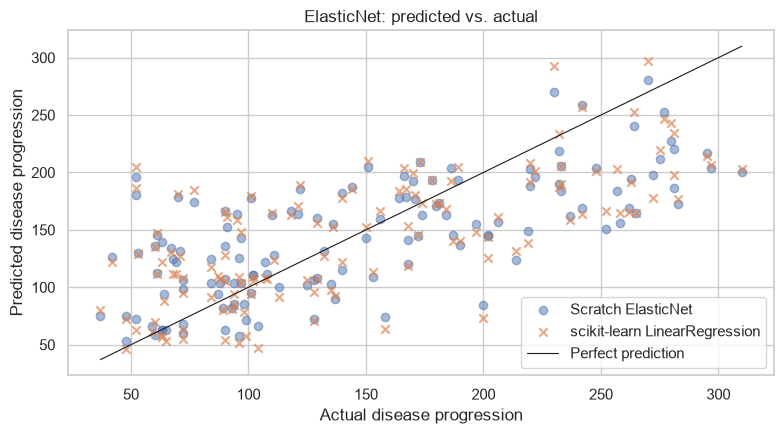

In [22]:
#Plotting
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(FIG_WIDTH, 4.5))
ax.scatter(y_test, scratch_preds, alpha=0.5, label="Scratch ElasticNet")
ax.scatter(y_test, sklearn_preds, alpha=0.7, marker="x", label="scikit-learn LinearRegression")
limits = [min(y_test.min(), scratch_preds.min(), sklearn_preds.min()), max(y_test.max(), scratch_preds.max(), sklearn_preds.max())]
ax.plot(limits, limits, color="k", linewidth=0.8, label="Perfect prediction")
ax.set_title("ElasticNet: predicted vs. actual")
ax.set_xlabel("Actual disease progression")
ax.set_ylabel("Predicted disease progression")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

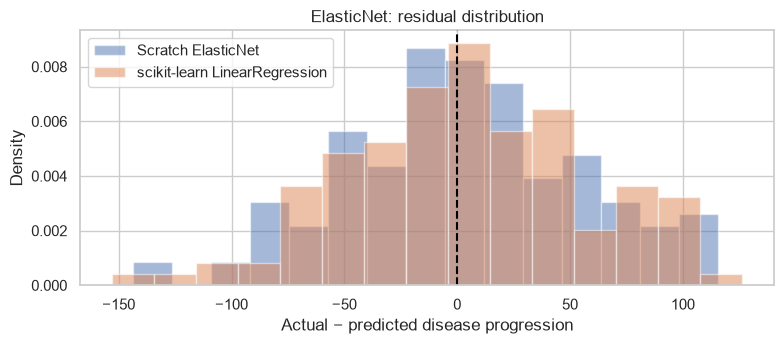

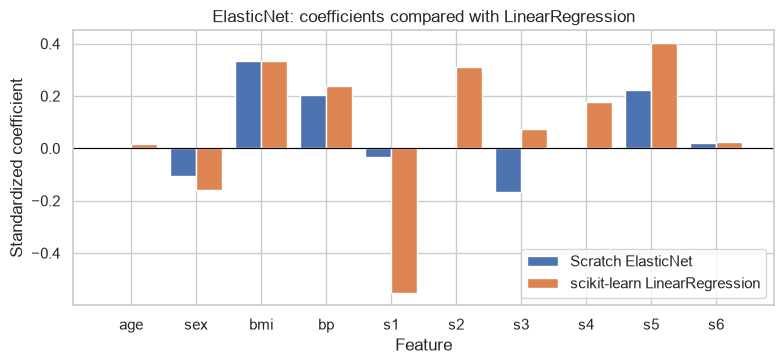

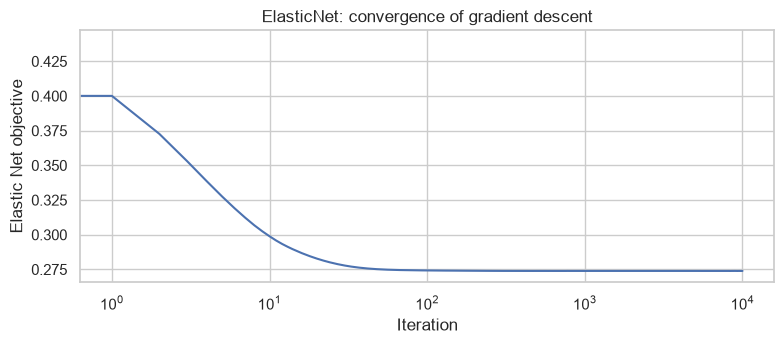

In [24]:
scratch_residuals = y_test - scratch_preds
sklearn_residuals = y_test - sklearn_preds
fig, ax = plt.subplots(figsize=(FIG_WIDTH, 3.6))
ax.hist(scratch_residuals, bins=15, alpha=0.5, density=True, label="Scratch ElasticNet")
ax.hist(sklearn_residuals, bins=15, alpha=0.5, density=True, label="scikit-learn LinearRegression")
ax.axvline(0, color="black", linestyle="--")
ax.set_title("ElasticNet: residual distribution")
ax.set_xlabel("Actual − predicted disease progression")
ax.set_ylabel("Density")
ax.legend()
fig.tight_layout()
plt.show()

indices = np.arange(X.shape[1])
width = 0.4
fig, ax = plt.subplots(figsize=(FIG_WIDTH, 3.8))
ax.bar(indices - width / 2, mymodel.W, width, label="Scratch ElasticNet")
ax.bar(indices + width / 2, sklearn_model.coef_, width, label="scikit-learn LinearRegression")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("ElasticNet: coefficients compared with LinearRegression")
ax.set_xlabel("Feature")
ax.set_ylabel("Standardized coefficient")
ax.set_xticks(indices)
ax.set_xticklabels(feature_names)
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

# objective vs iteration
fig, ax = plt.subplots(figsize=(FIG_WIDTH, 3.6))
ax.semilogx(mymodel.loss_history)
ax.set_xlabel("Iteration")
ax.set_ylabel("Elastic Net objective")
ax.set_title("ElasticNet: convergence of gradient descent")
fig.tight_layout()
plt.show()

In [25]:
#Analyse how the choice of parameters affects the model’s performance.

def iterate_the_params(param_name, param_values):
    results = []
    # original parameters
    base = {
        "learning_rate": 0.05,
        "iterations": 10000,
        "alpha": 0.05,
        "l1_ratio": 0.5,
    }

    for value in param_values:
        params = base.copy()
        if param_name=="l2_ratio":
            params["l1_ratio"]=1-value
        else:
            params[param_name] = value
        # convert into L1 and L2 penalties
        l1 = params["alpha"]*params["l1_ratio"]
        l2 = params["alpha"]*(1-params["l1_ratio"])
        model = ElasticNetRegression(
            learning_rate=params["learning_rate"],
            iterations=params["iterations"],
            l1_penalty=l1,
            l2_penalty=l2
        )
        model.fit(X_train_sc, y_train_sc)
        predictions_scaled = model.predict(X_test_sc)
        predictions = y_sc.inverse_transform(predictions_scaled.reshape(-1, 1)).ravel()
        mse = mean_squared_error(y_test, predictions)
        r2 = r2_score(y_test, predictions)
        results.append({
            "value": value,
            "mse": mse,
            "r2": r2,
        })

    return results

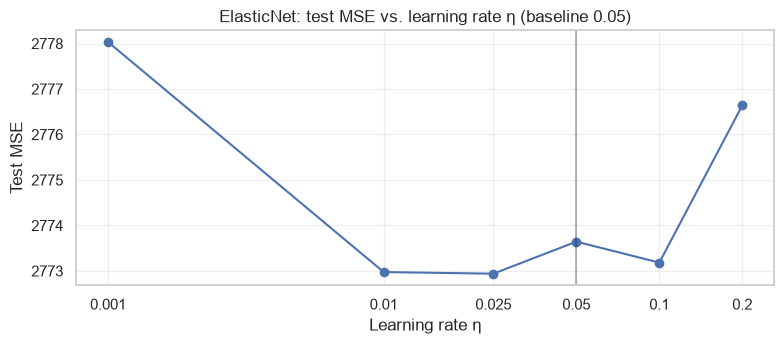

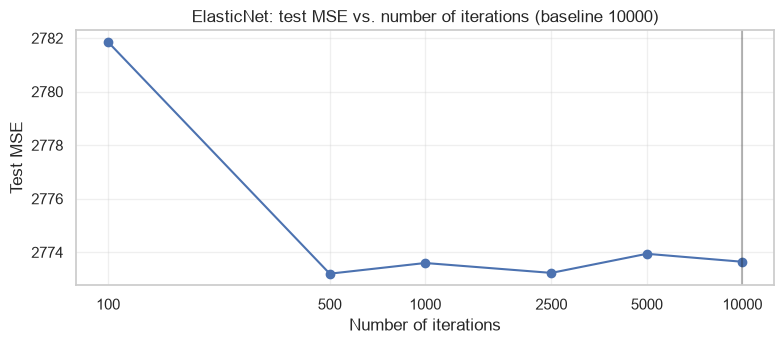

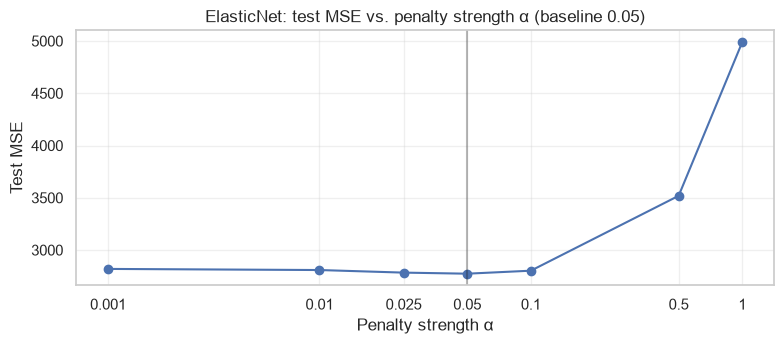

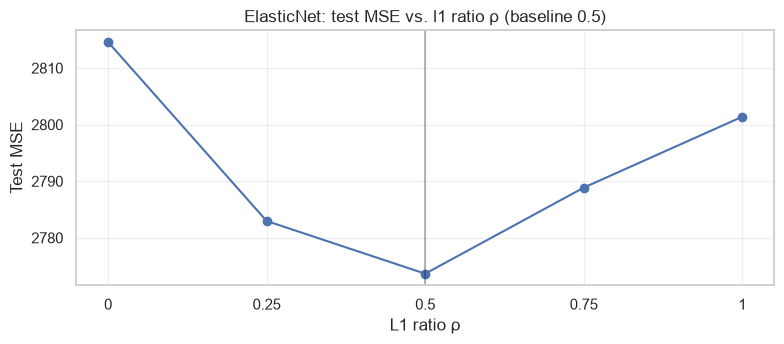

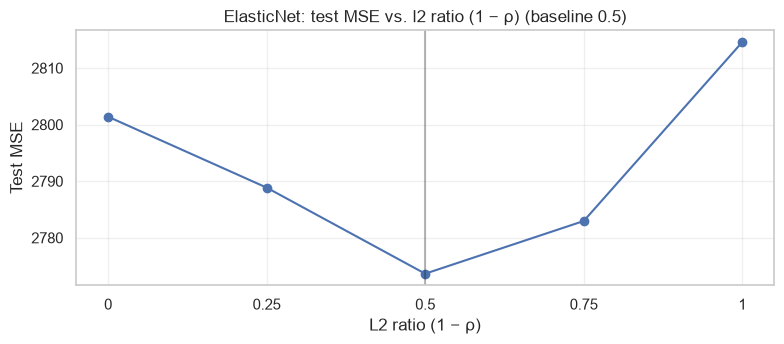

In [26]:
SWEEP_LABELS = {"learning_rate": "Learning rate η", "iterations": "Number of iterations", "alpha": "Penalty strength α",
                "l1_ratio": "L1 ratio ρ", "l2_ratio": "L2 ratio (1 − ρ)"}
SWEEP_BASELINE = {"learning_rate": 0.05, "iterations": 10000, "alpha": 0.05, "l1_ratio": 0.5, "l2_ratio": 0.5}
LOG_AXIS = {"learning_rate", "iterations", "alpha"}

# visualize the models performance
experiments = {
    "learning_rate": [0.001, 0.01, 0.025, 0.05, 0.1, 0.2],
    "iterations": [100, 500, 1000, 2500, 5000, 10000],
    "alpha": [0.001, 0.01, 0.025, 0.05, 0.1, 0.5, 1.0],
    "l1_ratio": [0.0, 0.25, 0.5, 0.75, 1.0],
    "l2_ratio": [0.0, 0.25, 0.5, 0.75, 1.0]
}

# plot: test MSE when one hyperparameter changes and the others stay at their baseline
for param_name, values in experiments.items():
    results = iterate_the_params(param_name, values)
    x = [r["value"] for r in results]
    mse = [r["mse"] for r in results]
    fig, ax = plt.subplots(figsize=(FIG_WIDTH, 3.6))
    ax.plot(x, mse, marker="o")
    ax.axvline(SWEEP_BASELINE[param_name], color="k", alpha=0.3)       # gray line: baseline value kept in the final model
    if param_name in LOG_AXIS:
        ax.set_xscale("log")
    ax.set_xticks(x)
    ax.set_xticklabels([f"{v:g}" for v in x])
    ax.minorticks_off()
    ax.set_xlabel(SWEEP_LABELS[param_name])
    ax.set_ylabel("Test MSE")
    ax.set_title(f"ElasticNet: test MSE vs. {SWEEP_LABELS[param_name].lower()} (baseline {SWEEP_BASELINE[param_name]:g})")
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    plt.show()


## Task 2: Lasso regression
The existing implementation, comparison and parameter experiments are retained unchanged.


In [27]:
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import seaborn as sns

class LassoRegression():

    def __init__(self, learning_rate, iterations, l1_penalty, l2_penalty):
        self.learning_rate = learning_rate
        self.iterations = iterations
        self.l1_penalty = l1_penalty
        self.l2_penalty = l2_penalty
        self.W = None
        self.b = None

    def fit(self, X, Y):
        self.m, self.n = X.shape
        self.W = np.zeros(self.n)
        self.b = 0.0
        self.X = X
        self.Y = Y
        self.loss_history = []
        for _ in range(self.iterations):
            self.update_weights()
        return self
    @staticmethod
    def soft_thresholding(x, threshold):
        return np.sign(x)*np.maximum(np.abs(x)-threshold, 0)

    def update_weights(self):
        Y_prediction = self.predict(self.X)
        #gradients
        grad_W = (self.X.T @ (Y_prediction - self.Y) / self.m)
        grad_b = np.mean(Y_prediction - self.Y)

        #gradient descent
        self.W -= self.learning_rate * grad_W
        self.b -= self.learning_rate * grad_b
        W_temp =self.W - self.learning_rate*grad_W
        self.W = self.soft_thresholding(W_temp, self.learning_rate*self.l1_penalty)

        # calculate objective function
        residuals = self.Y - self.predict(self.X)
        mse_loss = np.sum(residuals ** 2) / (2 * self.m)
        l1_loss = self.l1_penalty * np.sum(np.abs(self.W))
        self.loss_history.append(mse_loss + l1_loss)

    def predict(self, X):
        return X @ self.W + self.b


In [29]:
X, y = load_diabetes(return_X_y=True)
feature_names = load_diabetes().feature_names
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
X_sc = StandardScaler()
X_train_sc = X_sc.fit_transform(X_train)
X_test_sc = X_sc.transform(X_test)
y_sc = StandardScaler()
y_train_sc = y_sc.fit_transform(y_train.reshape(-1, 1)).ravel()

alpha = 0.05
l1_ratio = 0.5

l1_penalty = alpha*l1_ratio
l2_penalty = alpha*(1-l1_ratio)

mymodel = LassoRegression(
    learning_rate=0.05,
    iterations=10000,
    l1_penalty=alpha,
    l2_penalty=l2_penalty
)

mymodel.fit(X_train_sc, y_train_sc)
mymodel_n_iter = len(mymodel.loss_history)

sklearn_model = LinearRegression()

sklearn_model.fit(X_train_sc, y_train_sc)

scratch_scaled_preds = mymodel.predict(X_test_sc)
sklearn_scaled_preds = sklearn_model.predict(X_test_sc)

#unstandardize
scratch_preds = y_sc.inverse_transform(scratch_scaled_preds.reshape(-1, 1)).ravel()
sklearn_preds = y_sc.inverse_transform(sklearn_scaled_preds.reshape(-1, 1)).ravel()

def evaluate(name, y_true, predictions):
    print(f"{name}: test MSE {mean_squared_error(y_true, predictions):.2f}, R2 {r2_score(y_true, predictions):.4f}")


evaluate("Custom Lasso", y_test, scratch_preds)
evaluate("Scikit Learn LinearRegression", y_test, sklearn_preds)

print(f"Custom iterations: {mymodel_n_iter}")
print("Standardized coefficients:")
display(pd.DataFrame({"Lasso": mymodel.W, "LinearRegression": sklearn_model.coef_}, index=feature_names).round(3))


Custom Lasso: test MSE 2774.43, R2 0.4861
Scikit Learn LinearRegression: test MSE 2821.75, R2 0.4773
Custom iterations: 10000
Standardized coefficients:


,Lasso,LinearRegression
age,0.000,0.017
sex,-0.108,-0.159
bmi,0.342,0.334
bp,0.209,0.237
s1,-0.039,-0.552
s2,-0.000,0.309
s3,-0.167,0.073
s4,0.000,0.178
s5,0.230,0.403
s6,0.017,0.025


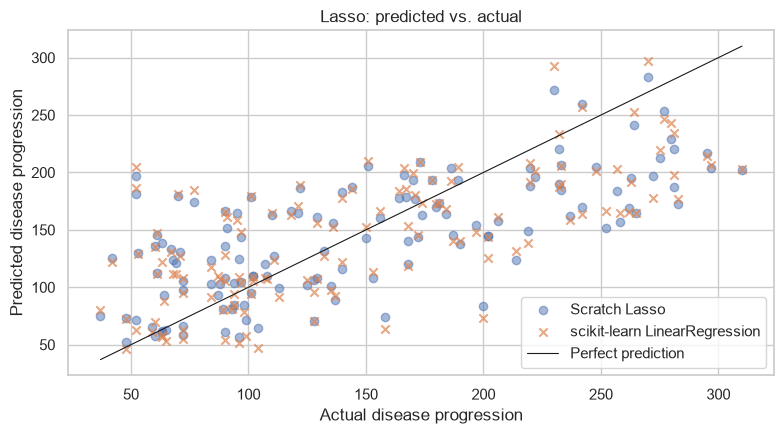

In [30]:
#Plotting
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(FIG_WIDTH, 4.5))
ax.scatter(y_test, scratch_preds, alpha=0.5, label="Scratch Lasso")
ax.scatter(y_test, sklearn_preds, alpha=0.7, marker="x", label="scikit-learn LinearRegression")
limits = [min(y_test.min(), scratch_preds.min(), sklearn_preds.min()), max(y_test.max(), scratch_preds.max(), sklearn_preds.max())]
ax.plot(limits, limits, color="k", linewidth=0.8, label="Perfect prediction")
ax.set_title("Lasso: predicted vs. actual")
ax.set_xlabel("Actual disease progression")
ax.set_ylabel("Predicted disease progression")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

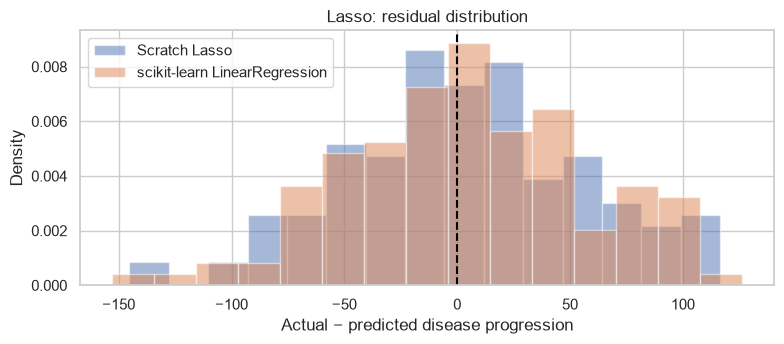

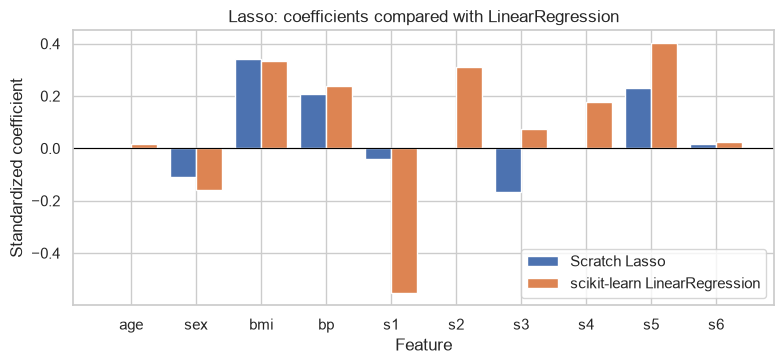

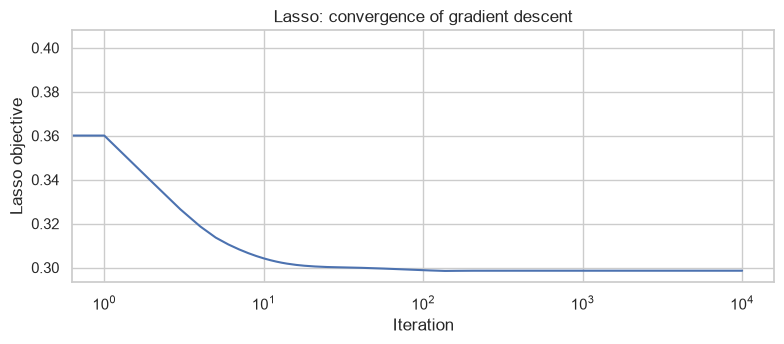

In [32]:
scratch_residuals = y_test - scratch_preds
sklearn_residuals = y_test - sklearn_preds
fig, ax = plt.subplots(figsize=(FIG_WIDTH, 3.6))
ax.hist(scratch_residuals, bins=15, alpha=0.5, density=True, label="Scratch Lasso")
ax.hist(sklearn_residuals, bins=15, alpha=0.5, density=True, label="scikit-learn LinearRegression")
ax.axvline(0, color="black", linestyle="--")
ax.set_title("Lasso: residual distribution")
ax.set_xlabel("Actual − predicted disease progression")
ax.set_ylabel("Density")
ax.legend()
fig.tight_layout()
plt.show()

indices = np.arange(X.shape[1])
width = 0.4
fig, ax = plt.subplots(figsize=(FIG_WIDTH, 3.8))
ax.bar(indices - width / 2, mymodel.W, width, label="Scratch Lasso")
ax.bar(indices + width / 2, sklearn_model.coef_, width, label="scikit-learn LinearRegression")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Lasso: coefficients compared with LinearRegression")
ax.set_xlabel("Feature")
ax.set_ylabel("Standardized coefficient")
ax.set_xticks(indices)
ax.set_xticklabels(feature_names)
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

# objective vs iteration
fig, ax = plt.subplots(figsize=(FIG_WIDTH, 3.6))
ax.semilogx(mymodel.loss_history)
ax.set_xlabel("Iteration")
ax.set_ylabel("Lasso objective")
ax.set_title("Lasso: convergence of gradient descent")
fig.tight_layout()
plt.show()

In [34]:
#Analyse how the choice of parameters affects the model’s performance.

def iterate_the_params(param_name, param_values):
    results = []
    # original parameters
    base = {
        "learning_rate": 0.05,
        "iterations": 10000,
        "alpha": 0.05,
        "l1_ratio": 0.5
    }
    for value in param_values:
        params = base.copy()
        params[param_name] = value
        # convert into L1 and L2 penalties
        l1 = params["alpha"]*params["l1_ratio"]
        l2 = params["alpha"]*(1-params["l1_ratio"])
        model = LassoRegression(
            learning_rate=params["learning_rate"],
            iterations=params["iterations"],
            l1_penalty=l1,
            l2_penalty=l2
        )
        model.fit(X_train_sc, y_train_sc)

        predictions_scaled = model.predict(X_test_sc)
        predictions = y_sc.inverse_transform(predictions_scaled.reshape(-1, 1)).ravel()
        mse = mean_squared_error(y_test, predictions)
        r2 = r2_score(y_test, predictions)
        results.append({
            "value": value,
            "mse": mse,
            "r2": r2,
        })
    return results

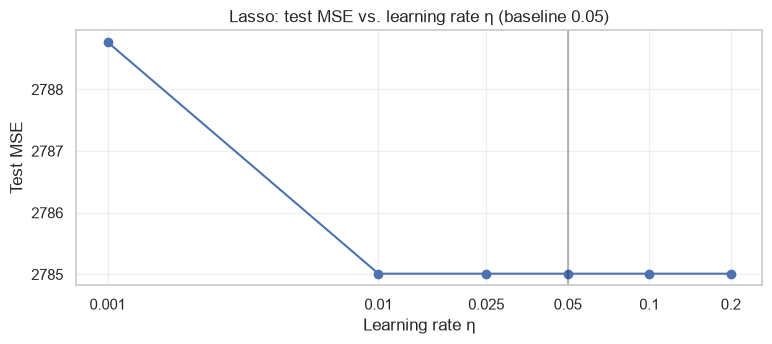

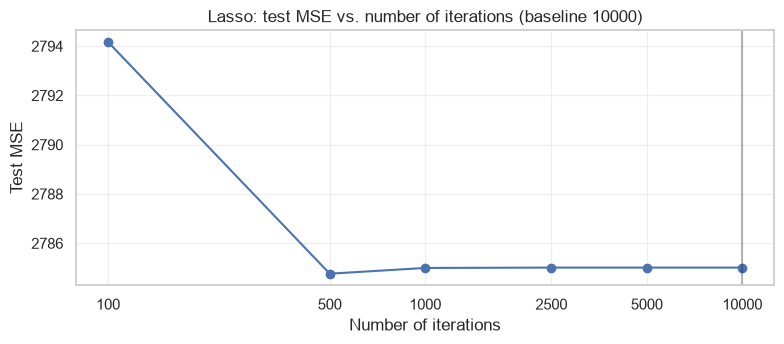

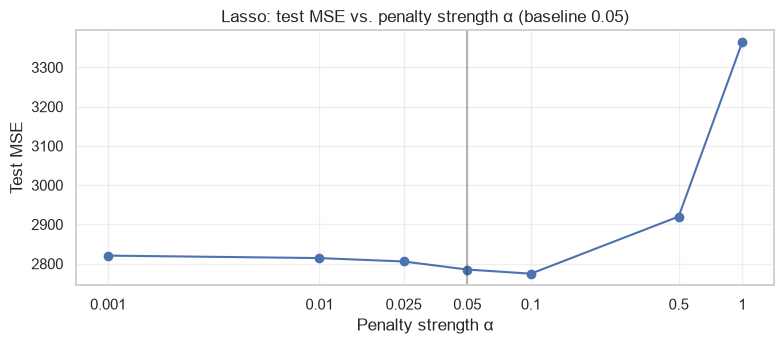

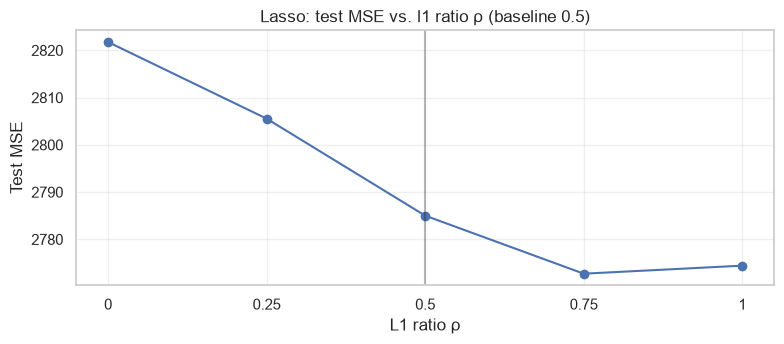

In [35]:
experiments = {
    "learning_rate": [0.001, 0.01, 0.025, 0.05, 0.1, 0.2],
    "iterations": [100, 500, 1000, 2500, 5000, 10000],
    "alpha": [0.001, 0.01, 0.025, 0.05, 0.1, 0.5, 1.0],
    "l1_ratio": [0.0, 0.25, 0.5, 0.75, 1.0]
}

# plot: test MSE when one hyperparameter changes and the others stay at their baseline
for param_name, values in experiments.items():
    results = iterate_the_params(param_name, values)
    x = [r["value"] for r in results]
    mse = [r["mse"] for r in results]
    fig, ax = plt.subplots(figsize=(FIG_WIDTH, 3.6))
    ax.plot(x, mse, marker="o")
    ax.axvline(SWEEP_BASELINE[param_name], color="k", alpha=0.3)       # gray line: baseline value kept in the final model
    if param_name in LOG_AXIS:
        ax.set_xscale("log")
    ax.set_xticks(x)
    ax.set_xticklabels([f"{v:g}" for v in x])
    ax.minorticks_off()
    ax.set_xlabel(SWEEP_LABELS[param_name])
    ax.set_ylabel("Test MSE")
    ax.set_title(f"Lasso: test MSE vs. {SWEEP_LABELS[param_name].lower()} (baseline {SWEEP_BASELINE[param_name]:g})")
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    plt.show()


## Task 1 and 2 - Digits Classification

Load dependencies and the Digits dataset, check for errorneous values, and plot the class sizes, pixel intensity distribution, and the distribution of the amount of ink in each image. The data is then split 70/30 into a training set and a test set.


Missing values: 0 | out-of-range values: 0


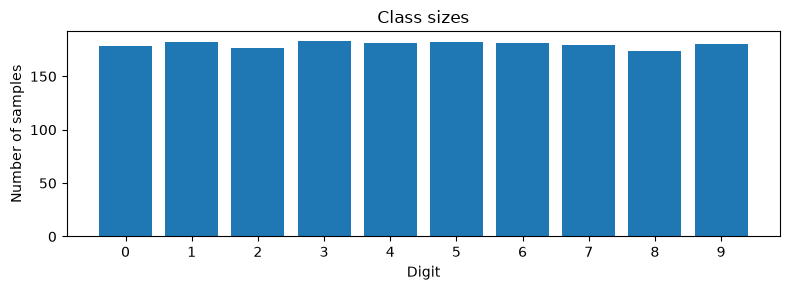

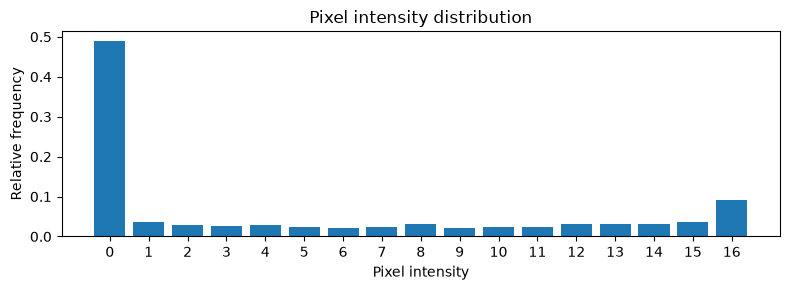

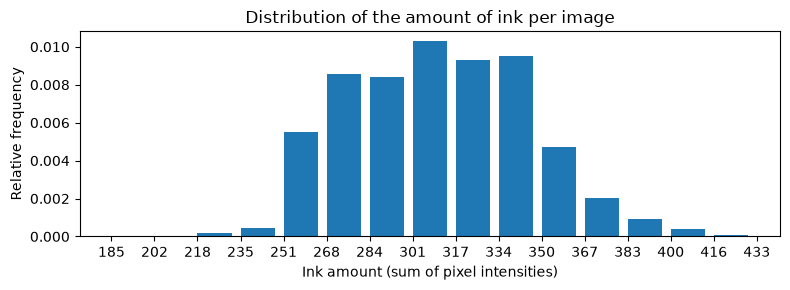

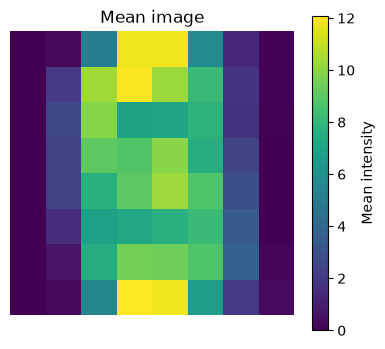

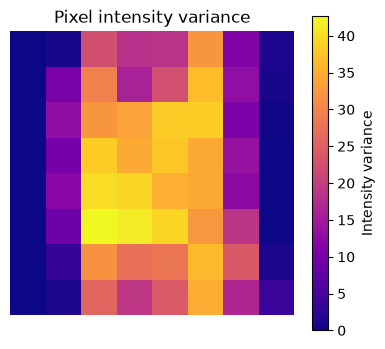

In [4]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA

digits = load_digits()
X, y = digits.data, digits.target

# Check for missing or out-of-range values (pixel intensities must lie between 0 and 16)
n_missing = int(np.isnan(X).sum())
n_out_of_range = int(((X < 0) | (X > 16)).sum())
print(f"Missing values: {n_missing} | out-of-range values: {n_out_of_range}")

# Plot class sizes
fig, ax = plt.subplots(figsize=(FIG_WIDTH, 3))
ax.bar(np.arange(10), np.bincount(y, minlength=10))
ax.set_xticks(np.arange(10))
ax.set_xlabel("Digit")
ax.set_ylabel("Number of samples")
ax.set_title("Class sizes")
fig.tight_layout()
plt.show()

# Plot pixel intensity distribution
dist, _ = np.histogram(X.reshape(-1), bins=np.arange(-0.5, 17.5, 1.0), density=True)
fig, ax = plt.subplots(figsize=(FIG_WIDTH, 3))
ax.bar(np.arange(0, 17), dist)
ax.set_xticks(np.arange(0, 17))
ax.set_xlabel("Pixel intensity")
ax.set_ylabel("Relative frequency")
ax.set_title("Pixel intensity distribution")
fig.tight_layout()
plt.show()

# Plot ink amount distribution
dist, bins = np.histogram(np.sum(X, axis=1), bins=15, density=True)
fig, ax = plt.subplots(figsize=(FIG_WIDTH, 3))
ax.bar(bins[:-1], dist, width=(bins[1]-bins[0])*4/5, align="edge")
ax.set_xticks(bins)
ax.set_xticklabels([f"{b:.0f}" for b in bins])
ax.set_xlabel("Ink amount (sum of pixel intensities)")
ax.set_ylabel("Relative frequency")
ax.set_title("Distribution of the amount of ink per image")
fig.tight_layout()
plt.show()

# Plot mean image and image variance
for image, cmap, label, title in [(X.mean(axis=0), "viridis", "Mean intensity", "Mean image"),
                                  (X.var(axis=0), "plasma", "Intensity variance", "Pixel intensity variance")]:
    fig, ax = plt.subplots(figsize=(4, 3.6))
    im = ax.imshow(image.reshape([8, 8]), cmap=cmap, interpolation="nearest")
    ax.axis("off")
    ax.set_title(title)
    fig.colorbar(im, ax=ax, label=label)
    fig.tight_layout()
    plt.show()

# 70/30 train/test split with seed 42. Stratification proves helpful
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

### Grid search implementation

In [5]:
import time
from collections.abc import Iterable
from itertools import product
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold

class Grid:
    def __init__(self, param_grid):
        self.keys = sorted(param_grid.keys())
        self.values = []
        for k in self.keys:
            if isinstance(param_grid[k], Iterable):
                self.values.append(param_grid[k])
            else:
                self.values.append([param_grid[k]])
        self.grid = np.zeros([len(l) for l in self.values]).tolist()

    def __getitem__(self, indices):
        g = self.grid
        for i in indices:
            g = g[i]
        return g

    def __setitem__(self, indices, value):
        g = self.grid
        for i in indices[:-1]:
            g = g[i]
        g[indices[-1]] = value

    def __iter__(self):
        return product(*(range(len(l)) for l in self.values))

    def index_to_params(self, idx):
        param_list = [self.values[i][j] for i, j in enumerate(idx)]
        return dict(zip(self.keys, param_list))

def accuracy(y_pred, y_true):
    return np.count_nonzero(y_pred == y_true) / y_pred.size

def cross_validate(build_model, params, X, y):
    scores = []
    fit_times = []
    # Without stratification validation scores are substantially lower than test scores
    for train_idx, val_idx in StratifiedKFold(5).split(X, y):
        model = build_model(params)
        # Fit on training set
        start = time.perf_counter()
        model.fit(X[train_idx], y[train_idx])
        fit_times.append(time.perf_counter() - start)
        # Score on validation set
        y_pred = model.predict(X[val_idx])
        scores.append(accuracy(y_pred, y[val_idx]))
    return {
        "test_score": np.mean(scores),
        "fit_time": np.mean(fit_times)
    }

def grid_search(build_model, param_grid, X, y):
    grid = Grid(param_grid)
    best_idx = None
    best_score = -np.inf
    total = int(np.prod([len(l) for l in grid.values]))
    for idx in grid:
        params = grid.index_to_params(idx)
        grid[idx] = cross_validate(build_model, params, X, y)
        score = grid[idx]["test_score"]
        if score > best_score:
            best_idx = idx
            best_score = score
    print(f"Grid search finished: {total} configurations, 5-fold cross-validation each")
    return grid, best_idx

# Helper methods
FIG_WIDTH = 8        
PARAM_LABELS = {"lambda_param": "Regularization strength λ", "learning_rate": "Learning rate",
                "n_iters": "Number of iterations", "hidden_size": "Hidden layer size",
                "epochs": "Number of epochs", "n_estimators": "Number of trees",
                "max_depth": "Maximum tree depth"}

def plot_line(xs, values, best_x, xscale, param, ylabel, title, ylim):
    fig, ax = plt.subplots(figsize=(FIG_WIDTH, 3.2))
    ax.axvline(best_x, color='k', alpha=0.3)               # gray line: selected value
    ax.plot(xs, values, 'o-')
    ax.set_xscale(xscale)
    ax.set_ylim(*ylim)
    ax.set_xticks(xs)
    ax.set_xticklabels([f"{x:.3g}" for x in xs])
    ax.minorticks_off()
    ax.set_xlabel(PARAM_LABELS.get(param, param))
    ax.set_ylabel(ylabel)
    ax.set_title(f"{title} (selected: {best_x:.3g})")
    fig.tight_layout()
    plt.show()

def plot_scores(xs, scores, best_x, xscale, param, title):
    ylim = (min(*scores, 1-2*(1-np.mean(scores))), 1)
    plot_line(xs, scores, best_x, xscale, param, "CV accuracy", f"{title}: CV accuracy vs. {PARAM_LABELS.get(param, param).lower()}", ylim)

def plot_fit_times(xs, fit_times, best_x, xscale, param, title):
    ylim = (0, 1.05 * max(*fit_times, 2*np.mean(fit_times)))
    plot_line(xs, fit_times, best_x, xscale, param, "Mean CV fit time (s)", f"{title}: fit time vs. {PARAM_LABELS.get(param, param).lower()}", ylim)

def plot_slices(grid, best_idx, config, title):
    for i, j in enumerate(best_idx):
        param = grid.keys[i]
        if param not in config:
            continue
        # Find scores and fit times along the i-th axis
        scores = []
        fit_times = []
        idx = list(best_idx)
        for k in range(len(grid.values[i])):
            idx[i] = k
            results = grid[idx]
            scores.append(results["test_score"])
            fit_times.append(results["fit_time"])
        xs = grid.values[i]
        if config[param][1] in ["accuracy", "both"]:
            plot_scores(xs, scores, xs[j], config[param][0], param, title)
        if config[param][1] in ["fit time", "both"]:
            plot_fit_times(xs, fit_times, xs[j], config[param][0], param, title)

### Multiclass SVM

Use grid search to find the best lambda and learning rate with a fixed number of iterations. Variate each of these parameters with the other fixed to the best values and plot the cross-validation accuracy.


In [6]:
import numpy as np

# One-vs-rest linear SVM trained with full-batch gradient descent
class MulticlassSVM:
    def __init__(self, learning_rate, lambda_param, n_iters):
        self.learning_rate = learning_rate
        self.lambda_param = lambda_param
        self.n_iters = n_iters

        self.weights = None
        self.biases = None
        self.classes = None

    def train_binary(self, X, y_bin):
        w = np.zeros(X.shape[1])
        b = 0.0
        for _ in range(self.n_iters):
            scores = X @ w + b
            margins = y_bin * scores
            mask = margins < 1
            grad_w = self.lambda_param * w
            if np.any(mask):
                grad_w -= (X[mask].T @ y_bin[mask]) / X.shape[0]
                grad_b = -np.sum(y_bin[mask]) / X.shape[0]
            else:
                grad_b = 0.0
            w -= self.learning_rate * grad_w
            b -= self.learning_rate * grad_b
        return w, b

    def fit(self, X, y):
        self.classes = np.unique(y)
        n_features = X.shape[1]
        n_classes = len(self.classes)

        self.weights = np.zeros((n_classes, n_features))
        self.biases = np.zeros(n_classes)

        for i, c in enumerate(self.classes):
            w, b = self.train_binary(X, (y == c)*2-1)
            self.weights[i] = w
            self.biases[i] = b

        return self

    def predict(self, X):
        assert self.weights is not None
        assert self.biases is not None
        assert self.classes is not None

        scores = X @ self.weights.T + self.biases
        idx = np.argmax(scores, axis=1)
        return self.classes[idx]

Grid search finished: 49 configurations, 5-fold cross-validation each
Best validation accuracy: 0.9602
Best hyperparameters: {'lambda_param': 1e-05, 'learning_rate': 0.01, 'n_iters': 400}


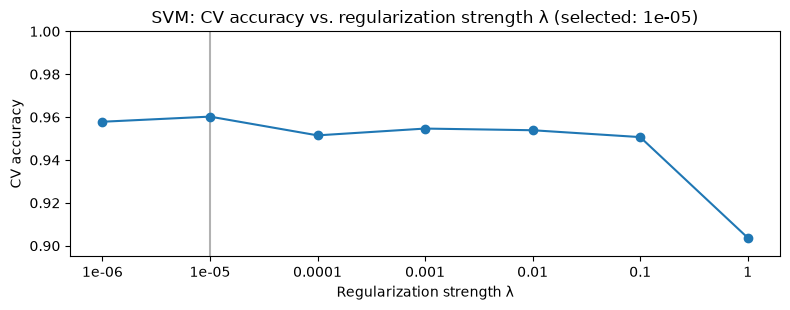

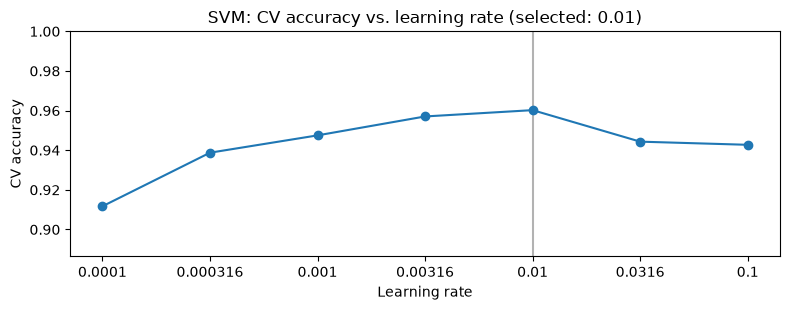

In [8]:
svm_grid = {
    "lambda_param": np.logspace(-6, 0, 7).tolist(),
    "learning_rate": np.logspace(-4, -1, 7).tolist(),
    "n_iters": 400
}
svm_plot_config = {
    "lambda_param": ("log", "accuracy"),
    "learning_rate": ("log", "accuracy")
}
build_svm = lambda p: MulticlassSVM(**p)
grid, best_idx = grid_search(build_svm, svm_grid, X_train, y_train)
svm_best_params = grid.index_to_params(best_idx)
print(f"Best validation accuracy: {grid[best_idx]['test_score']:.4f}")
print("Best hyperparameters:", svm_best_params)
plot_slices(grid, best_idx, svm_plot_config, "SVM")


Variate the number of iterations and plot the cross-validation accuracy and the mean training time during cross-validation.


Grid search finished: 6 configurations, 5-fold cross-validation each


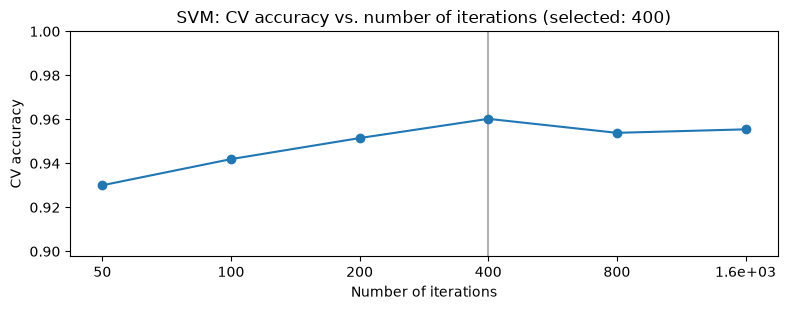

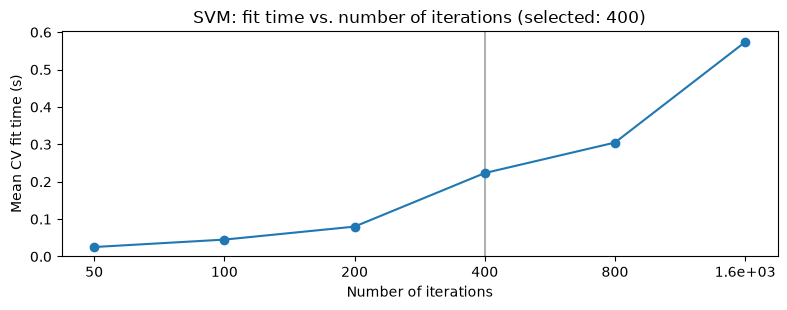

In [9]:
params = svm_best_params.copy()
params["n_iters"] = [50, 100, 200, 400, 800, 1600]
grid, best_idx = grid_search(build_svm, params, X_train, y_train)
params = grid.index_to_params(best_idx)
plot_slices(grid, best_idx, {"n_iters": ("log", "both")}, "SVM")


Train the model on the entire training set and test with the test set. Report prediction time and accuracy.


In [10]:
svm = build_svm(svm_best_params).fit(X_train, y_train)
start = time.perf_counter()
y_pred = svm.predict(X_test)
pred_time = time.perf_counter() - start
print(f"Prediction time on test set: {pred_time*1000:.4f} ms")
print(f"Accuracy on test set: {accuracy(y_pred, y_test):.4f}")


Prediction time on test set: 1.3407 ms
Accuracy on test set: 0.9556


Find the two principal values to map the data to 2D, optimize the hyperparameters by grid search and plot the decision boundaries.


Grid search finished: 15 configurations, 5-fold cross-validation each
Best validation accuracy: 0.5643
Best hyperparameters: {'lambda_param': 31.622776601683793, 'learning_rate': 0.0001, 'n_iters': 400}


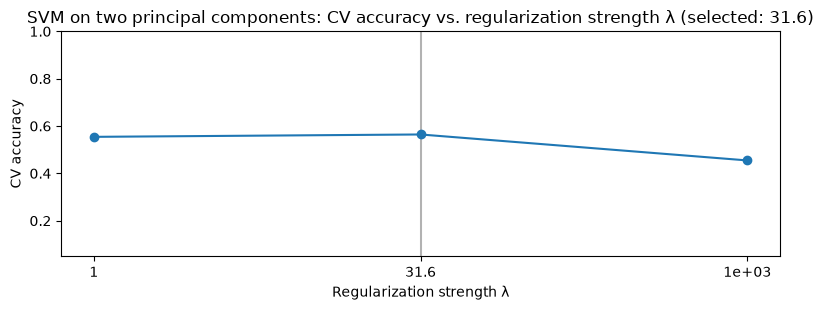

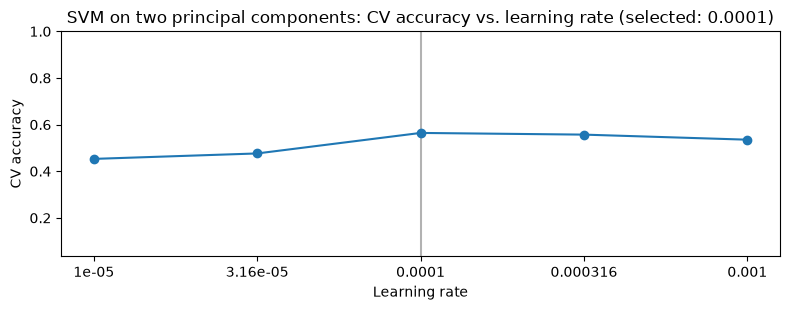

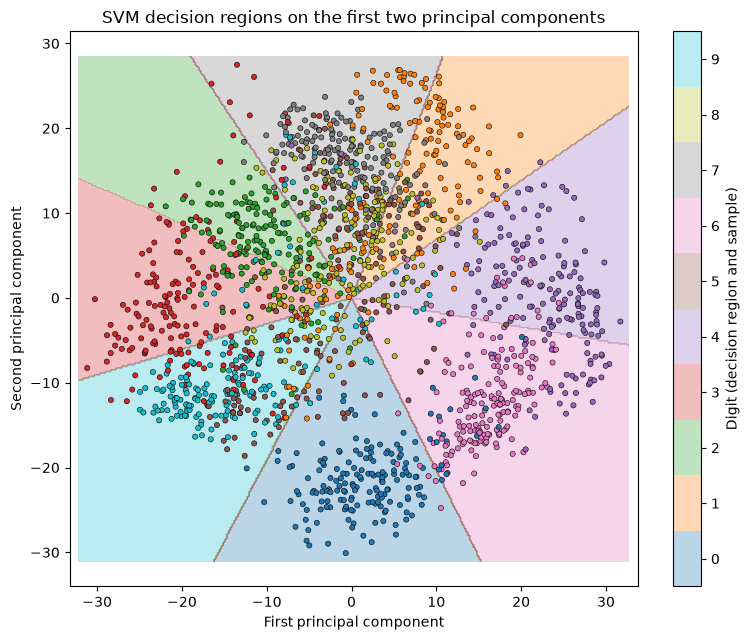

In [11]:
svm_grid = {
    "lambda_param": np.logspace(0, 3, 3).tolist(),
    "learning_rate": np.logspace(-5, -3, 5).tolist(),
    "n_iters": 400
}
X_2D = PCA(n_components=2).fit_transform(X)
grid, best_idx = grid_search(build_svm, svm_grid, X_2D, y)
svm_best_params = grid.index_to_params(best_idx)
print(f"Best validation accuracy: {grid[best_idx]['test_score']:.4f}")
print("Best hyperparameters:", svm_best_params)
plot_slices(grid, best_idx, svm_plot_config, "SVM on two principal components")
x_min = X_2D[:,0].min() - 1
x_max = X_2D[:,0].max() + 1
y_min = X_2D[:,1].min() - 1
y_max = X_2D[:,1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
X_mesh = np.column_stack((xx.ravel(), yy.ravel()))
svm = build_svm(svm_best_params).fit(X_2D, y)
Z = svm.predict(X_mesh).reshape(xx.shape)
fig, ax = plt.subplots(figsize=(FIG_WIDTH, 6.5))
cs = ax.contourf(xx, yy, Z, levels=np.arange(-0.5, 10), alpha=0.3, cmap='tab10')
cbar = fig.colorbar(cs, label="Digit (decision region and sample)")
cbar.set_ticks(range(0, 10))
ax.scatter(X_2D[:, 0], X_2D[:, 1], c=y, cmap='tab10', vmin=-0.5, vmax=9.5, edgecolors='k', linewidths=0.4, s=14)
ax.axis('equal')
ax.set_xlabel("First principal component")
ax.set_ylabel("Second principal component")
ax.set_title("SVM decision regions on the first two principal components")
fig.tight_layout()
plt.show()


### 2-layer MLP

Use grid search to find the best hidden layer size and learning rate with a fixed epochs. Variate each of these parameters with the other fixed to the best values and plot the cross-validation accuracy. The mean training time during cross-validation vs. the hidden layer size is also plotted.


In [12]:
import numpy as np

def relu(z):
    return np.maximum(0, z)

def relu_deriv(z):
    return z > 0

def softmax(z):
    exp_z = np.exp(z - np.max(z, axis=0))
    return exp_z / np.sum(exp_z, axis=0)

# 2-layer MLP (input -> ReLU hidden -> softmax) using full-batch gradient descent
class MLP:
    def __init__(self, input_size, hidden_size, output_size, lr):
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.lr = lr
        rng = np.random.default_rng(42)
        self.W1 = rng.normal(0, 0.001, size=(hidden_size, input_size))
        self.b1 = np.zeros((hidden_size, 1))
        self.W2 = rng.normal(0, 0.001, size=(output_size, hidden_size))
        self.b2 = np.zeros((output_size, 1))

    def fit(self, X, y, epochs):
        a0 = X.T
        y = np.eye(self.output_size)[y].T  # One-hot encoding

        for _ in range(epochs):
            # Forward pass
            z1 = self.W1 @ a0 + self.b1
            a1 = relu(z1)
            z2 = self.W2 @ a1
            a2 = softmax(z2)
            # Backpropagation
            grad_z2 = a2 - y
            grad_W2 = grad_z2 @ a1.T / X.shape[0]
            grad_b2 = np.mean(grad_z2, axis=1, keepdims=True)
            grad_a1 = self.W2.T @ grad_z2
            grad_z1 = grad_a1 * relu_deriv(z1)
            grad_W1 = grad_z1 @ a0.T / X.shape[0]
            grad_b1 = np.mean(grad_z1, axis=1, keepdims=True)

            self.W2 -= self.lr * grad_W2
            self.b2 -= self.lr * grad_b2
            self.W1 -= self.lr * grad_W1
            self.b1 -= self.lr * grad_b1

        return self

    def predict(self, X):
        z1 = self.W1 @ X.T + self.b1
        z2 = self.W2 @ relu(z1) + self.b2
        return np.argmax(z2, axis=0).T
    
class MLP2(MLP):
    def __init__(self, input_size, hidden_size, output_size, learning_rate, epochs):
        self.epochs = epochs
        super().__init__(input_size, hidden_size, output_size, learning_rate)

    def fit(self, X, y):
        super().fit(X, y, self.epochs)
        return self

Grid search finished: 28 configurations, 5-fold cross-validation each
Best validation accuracy: 0.9674
Best hyperparameters: {'epochs': 400, 'hidden_size': 64, 'learning_rate': 0.046415888336127795}


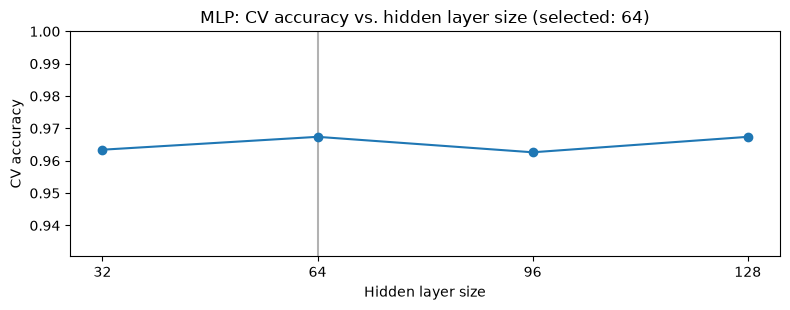

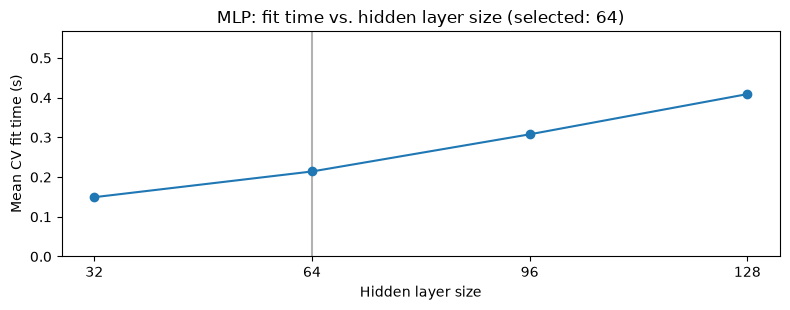

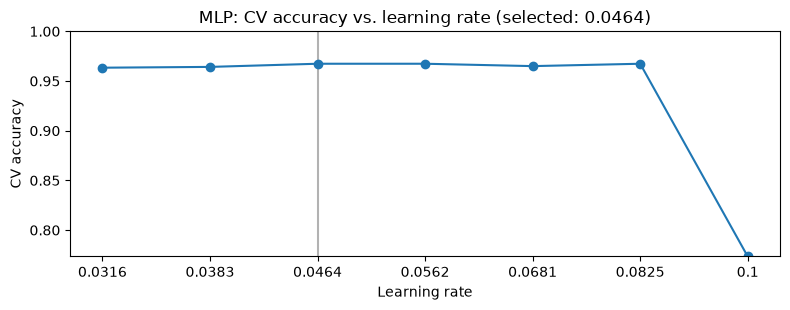

In [13]:
mlp_grid = {
    "hidden_size": [32, 64, 96, 128],
    "learning_rate": np.logspace(-1.5, -1, 7).tolist(),
    "epochs": 400
}
mlp_plot_config = {
    "hidden_size": ("linear", "both"),
    "learning_rate": ("log", "accuracy")
}
build_mlp = lambda p: MLP2(input_size=X.shape[1], output_size=10, **p)
grid, best_idx = grid_search(build_mlp, mlp_grid, X_train, y_train)
mlp_best_params = grid.index_to_params(best_idx)
print(f"Best validation accuracy: {grid[best_idx]['test_score']:.4f}")
print("Best hyperparameters:", mlp_best_params)
plot_slices(grid, best_idx, mlp_plot_config, "MLP")


Variate the epochs and plot the cross-validation accuracy and the mean training time during cross-validation.


Grid search finished: 5 configurations, 5-fold cross-validation each


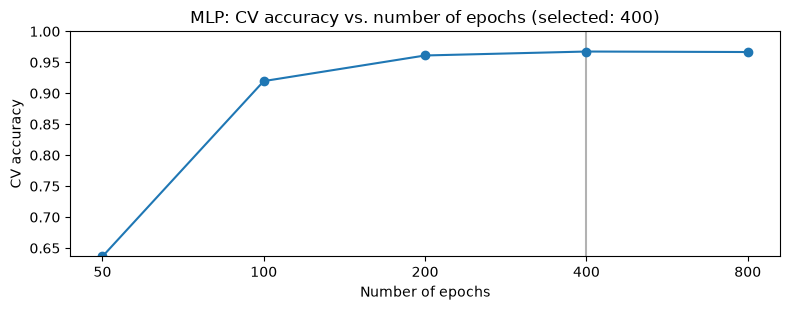

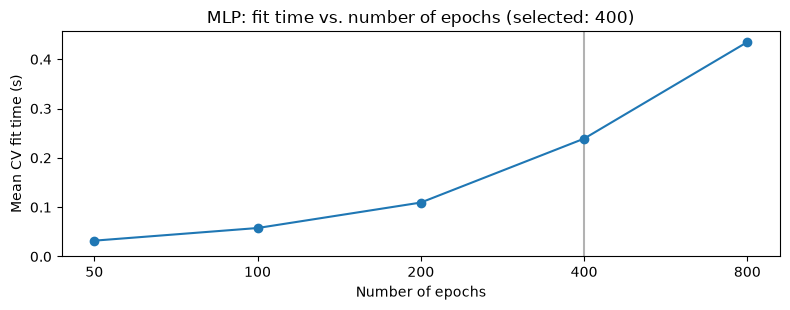

In [14]:
params = mlp_best_params.copy()
params["epochs"] = [50, 100, 200, 400, 800]
grid, best_idx = grid_search(build_mlp, params, X_train, y_train)
params = grid.index_to_params(best_idx)
plot_slices(grid, best_idx, {"epochs": ("log", "both")}, "MLP")


Train the model on the entire training set and test with the test set. Report prediction time and accuracy.


In [15]:
mlp = build_mlp(mlp_best_params).fit(X_train, y_train)
start = time.perf_counter()
y_pred = mlp.predict(X_test)
pred_time = time.perf_counter() - start
print(f"Prediction time on test set: {pred_time*1000:.4f} ms")
print(f"Accuracy on test set: {accuracy(y_pred, y_test):.4f}")


Prediction time on test set: 0.2845 ms
Accuracy on test set: 0.9611


### Random Forest Classifier

Use grid search to find the best number of estimators and the best maximum depth. Variate each of these parameters with the other fixed to the best values and plot the cross-validation accuracy.


Grid search finished: 25 configurations, 5-fold cross-validation each
Best validation accuracy: 0.9745
Best hyperparameters: {'max_depth': 10, 'n_estimators': 100}


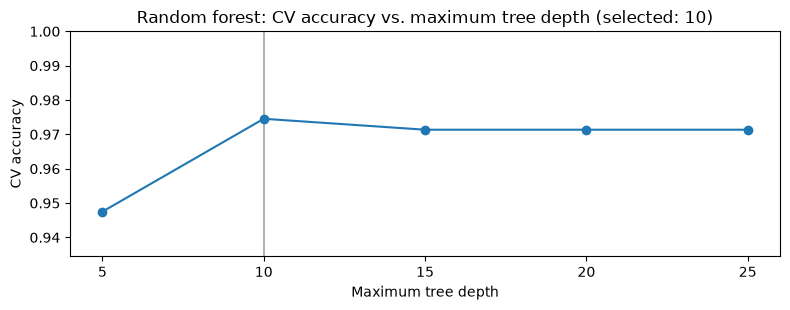

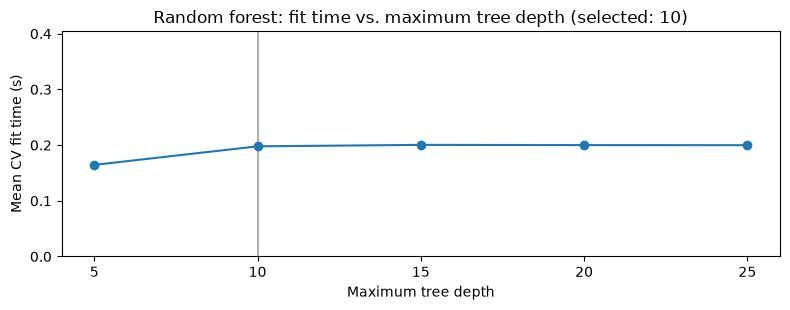

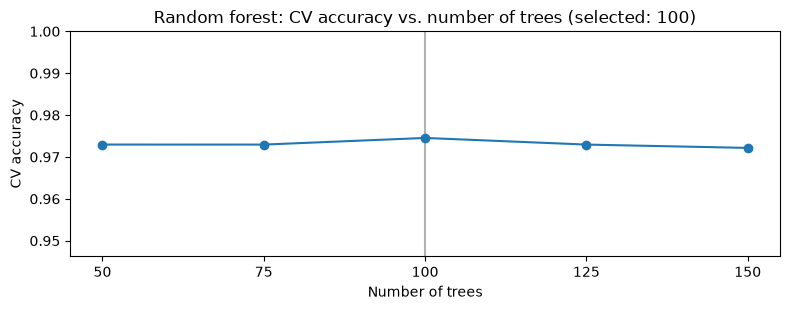

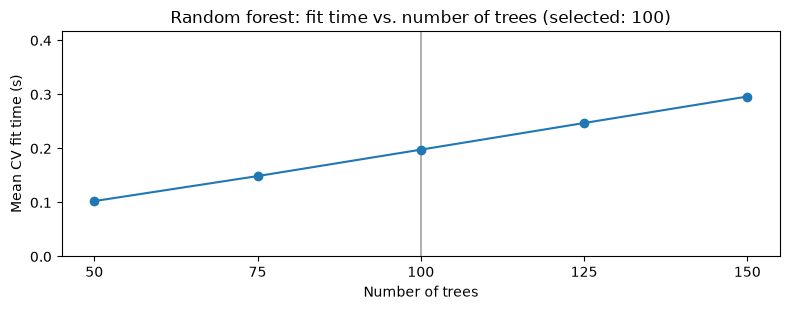

In [16]:
rf_grid = {
    "n_estimators": [50, 75, 100, 125, 150],
    "max_depth": [5, 10, 15, 20, 25],
}
rf_plot_config = {
    "n_estimators": ("linear", "both"),
    "max_depth": ("linear", "both")
}
build_rf = lambda p: RandomForestClassifier(random_state=42, **p)
grid, best_idx = grid_search(build_rf, rf_grid, X_train, y_train)
rf_best_params = grid.index_to_params(best_idx)
print(f"Best validation accuracy: {grid[best_idx]['test_score']:.4f}")
print("Best hyperparameters:", rf_best_params)
plot_slices(grid, best_idx, rf_plot_config, "Random forest")


Train the model on the entire training set and test with the test set. Report prediction time and accuracy.


In [17]:
rf = build_rf(rf_best_params).fit(X_train, y_train)
start = time.perf_counter()
y_pred = rf.predict(X_test)
pred_time = time.perf_counter() - start
print(f"Prediction time on test set: {pred_time*1000:.4f} ms")
print(f"Accuracy on test set: {accuracy(y_pred, y_test):.4f}")


Prediction time on test set: 10.0293 ms
Accuracy on test set: 0.9685


# Task 3 — Predicting tomorrow's stock returns

## 3.1 Problem and experimental protocol
We predict the **next trading day's volatility-adjusted excess return** for current S&P 500 members.
Returns span 1980–2013; sentiment starts in July 2009. Membership changes over time, so we use
the membership list on the prediction date, not today's surviving companies.

We compare a sparse linear model (Lasso), a random forest and a small MLP with two simple rules.
Development outcomes are **1990–2010**; test outcomes are **2011–2013**. Features observed at close
\(t\) predict the return from close \(t\) to close \(t+1\). A fitted model may use only labels
realized **before** \(t\). Earlier test observations may enter later scheduled refits; test
performance never selects hyperparameters.

**Disclosure:** this compact study replaces a larger study whose test results were already viewed.
Its test period is therefore not a fresh, untouched test. The grids below are fixed before this
new run; we report negative or inconclusive outcomes as well as positive ones.

| Step | Information allowed |
|---|---|
| Feature row at close \(t\) | Returns through \(t\), sentiment dated before \(t\) |
| Fit used on \(t\) | Training outcomes realized strictly before \(t\) |
| Target of row \(t\) | Adjusted return realized on the next observed trading date |
| Membership and prediction centering | Members known on \(t\), before seeing the target |


In [7]:
import json
import time
import warnings
import importlib.metadata
from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.linear_model import Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.exceptions import ConvergenceWarning

DATA_DIR = Path("data")  # Change this one setting to the folder containing the supplied CSVs.
if not DATA_DIR.is_dir() and (Path("..") / DATA_DIR).is_dir():
    DATA_DIR = Path("..") / DATA_DIR  # Also supports opening the notebook from notebooks/.
plt.rcParams.update({"font.size": 11, "figure.figsize": (10, 4)})
pd.set_option("display.max_rows", 25, "display.max_columns", 20)
START_TIME = time.perf_counter()
print("Package versions:", {p: importlib.metadata.version(p) for p in
                            ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib"]})


Package versions: {'numpy': '2.4.6', 'pandas': '3.0.5', 'scipy': '1.17.1', 'scikit-learn': '1.9.0', 'matplotlib': '3.11.1'}


## 3.2 Loading, cleaning and exploratory analysis
We align the return and membership tables by date and security ID. A repeated permno denotes
distinct securities, so we retain the second column with an `_b` suffix rather than averaging
it into the first. Entirely empty securities are removed. Missing returns remain missing;
we never invent a target. Available nonmember history can estimate volatility, but only
current members enter model training, cross-sectional ranks and evaluation.


In [14]:
def load_data(data_dir):
    """Load and align the supplied equities; preserve distinct duplicated securities."""
    
    returns = pd.read_csv(data_dir / "eq_returns.csv", index_col="date", parse_dates=True)
    indicator = pd.read_csv(data_dir / "eq_indicator.csv", index_col="date", parse_dates=True)
    metadata = pd.read_csv(data_dir / "eq_stock_metadata.csv")
    
    ambiguous = metadata.loc[metadata.permno.duplicated(keep=False), "permno"].astype(str).unique()
    rename = lambda columns: [c[:-2] + "_b" if c.endswith(".1") else c for c in columns]
    returns.columns, indicator.columns = rename(returns.columns), rename(indicator.columns)
    metadata["id"] = metadata.permno.astype(str)
    metadata.loc[metadata.permno.duplicated(), "id"] += "_b"
    metadata = metadata.set_index("id")
    
    assert returns.index.is_monotonic_increasing and not returns.index.has_duplicates
    assert returns.index.equals(indicator.index) and returns.columns.equals(indicator.columns)
    assert indicator.isin([0, 1]).all().all(), "Membership must contain only 0 or 1"
    assert not np.isinf(returns.to_numpy()).any(), "Infinite returns must be investigated"
    
    empty = returns.columns[returns.isna().all()]  # Drop columns that are all NaN
    returns, indicator = returns.drop(columns=empty), indicator.drop(columns=empty)
    metadata = metadata.loc[returns.columns]
    
    cleaning = {"renamed_duplicates": sum(c.endswith("_b") for c in indicator.columns),
                "empty_columns_removed": len(empty), "ambiguous_sentiment_ids": list(ambiguous)}
    
    return returns, indicator.eq(1), metadata, cleaning


def volatility(returns, beta1=0.97, beta2=0.99, initial_variance=0.02**2, burn_in=100):
    """Assignment EWMAs: end-of-day sigma uses observations through that day only."""
    
    mean = np.zeros(returns.shape[1])
    variance = np.full(returns.shape[1], initial_variance)
    seen = np.zeros(returns.shape[1], dtype=int)
    sigma = np.full(returns.shape, np.nan)
    
    for t, row in enumerate(returns.to_numpy()):
        observed = np.isfinite(row)
        mean[observed] = (1 - beta2) * row[observed] + beta2 * mean[observed]
        residual = row[observed] - mean[observed]
        variance[observed] = (1 - beta1) * residual**2 + beta1 * variance[observed]
        seen[observed] += 1
        ready = seen >= burn_in
        sigma[t, ready] = np.sqrt(variance[ready])  # Carry past estimates over gaps; never look forward.
        
    return pd.DataFrame(sigma, index=returns.index, columns=returns.columns)

The assignment estimates a changing mean and variance:
\[
\hat\mu_t=(1-0.99)r_t+0.99\hat\mu_{t-1},\qquad
\hat\sigma_t^2=(1-0.97)(r_t-\hat\mu_t)^2+0.97\hat\sigma_{t-1}^2.
\]
We use \(\tilde r_t=r_t/\hat\sigma_{t-1}\), with initial variance \(0.02^2\) and a
100-observation burn-in. The lag prevents the denominator from using the return it adjusts.
Clipping to \([-5,5]\) limits extreme values in features and fitted targets; evaluation uses
the original, unclipped adjusted returns. All exploratory statistics below use pre-2011 data.


In [28]:
returns, members, metadata, cleaning = load_data(DATA_DIR)
sigma = volatility(returns)
adjusted_returns = returns / sigma.shift(1)  # Day t is divided by the estimate from t-1.
clipped_returns = adjusted_returns.clip(-5, 5)
outcome_dates = pd.Series(returns.index, index=returns.index).shift(-1)  # Next trading day, not +1 calendar day.
actual_outcomes = adjusted_returns.shift(-1)  # Feature row t is scored against the unclipped return on t+1.
target = clipped_returns.shift(-1).where(members)  # Clipped next-day outcome for prediction-day members.
target = target.sub(target.mean(axis=1), axis=0)  # Cross-sectional target mean is known when its outcome is realized.
dev_members = members.loc[:"2010-12-31"]
raw_sample = returns.loc[dev_members.index].where(dev_members).stack()
adjusted_sample = adjusted_returns.loc[dev_members.index].where(dev_members).stack()
display(pd.DataFrame({"Raw return": raw_sample.describe(percentiles=[.01, .5, .99]),
                      "Adjusted return": adjusted_sample.describe(percentiles=[.01, .5, .99])}))
print("Securities retained:", len(metadata), "| Empty columns removed:", cleaning["empty_columns_removed"])
print("Development member counts (minimum/mean):", dev_members.sum(axis=1).min(),
      round(dev_members.sum(axis=1).mean(), 1))
print("Missing development member returns:", int((returns.loc[dev_members.index].isna() & dev_members).sum().sum()))
print("Development nonmember returns excluded from fitting:",
      int((returns.loc[dev_members.index].notna() & ~dev_members).sum().sum()))
display(Markdown(f"Raw member returns have excess kurtosis **{raw_sample.kurt():.1f}**, "
                 f"versus **{adjusted_sample.kurt():.1f}** after adjustment. "
                 f"**{(adjusted_sample.abs() > 5).mean():.2%}** of adjusted values exceed ±5. "
                 "Adjustment improves comparability, but heavy tails remain; this motivates clipping for fitting and ranking the features."))


,Raw return,Adjusted return
count,3.909756e+06,3.851495e+06
mean,6.038844e-04,3.357618e-02
std,2.428898e-02,1.057297e+00
min,-9.424660e-01,-3.156312e+01
1%,-6.250000e-02,-2.529317e+00
50%,0.000000e+00,0.000000e+00
99%,6.919045e-02,2.809489e+00
max,1.023578e+00,5.639968e+01


Securities retained: 1314 | Empty columns removed: 21
Development member counts (minimum/mean): 489 499.8
Missing development member returns: 0
Development nonmember returns excluded from fitting: 2106407


Raw member returns have excess kurtosis **39.3**, versus **22.5** after adjustment. **0.20%** of adjusted values exceed ±5. Adjustment improves comparability, but heavy tails remain; this motivates clipping for fitting and ranking the features.

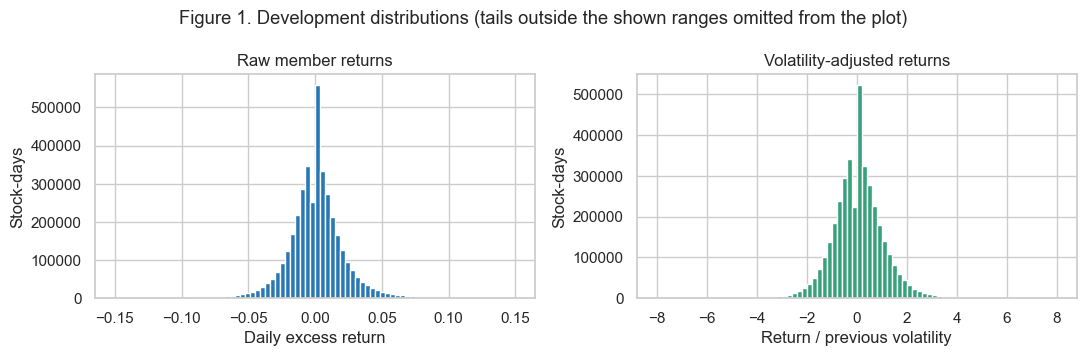

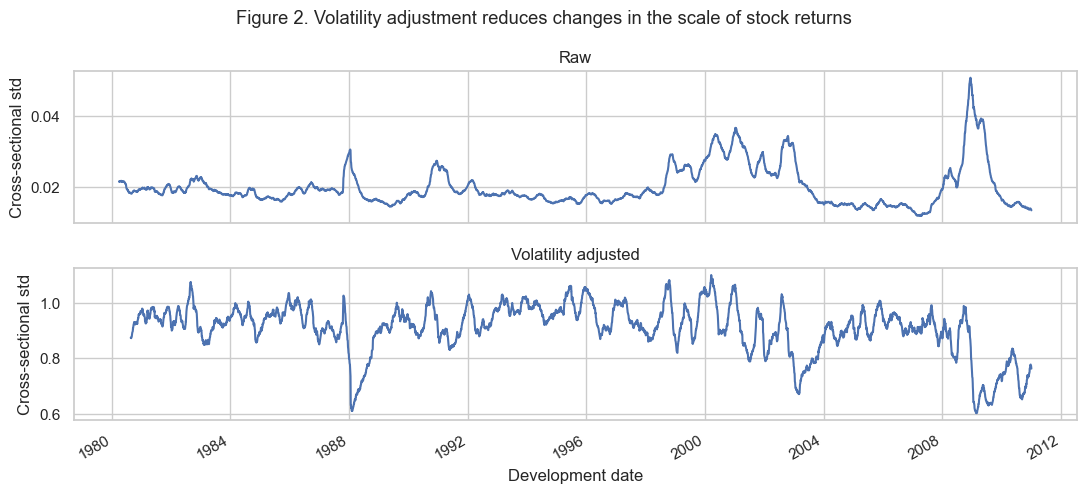

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(raw_sample, bins=np.linspace(-.15, .15, 81), color="#2878b5")
axes[1].hist(adjusted_sample, bins=np.linspace(-8, 8, 81), color="#36a17b")
for ax, title, label in zip(axes, ["Raw member returns", "Volatility-adjusted returns"],
                          ["Daily excess return", "Return / previous volatility"]):
    ax.set(title=title, xlabel=label, ylabel="Stock-days")
fig.suptitle("Figure 1. Development distributions (tails outside the shown ranges omitted from the plot)")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
for ax, data, title in zip(axes, [returns, adjusted_returns], ["Raw", "Volatility adjusted"]):
    dispersion = data.loc[dev_members.index].where(dev_members).std(axis=1)
    dispersion.rolling(63).mean().plot(ax=ax)  # Each displayed average uses only the preceding 63 trading days.
    ax.set(ylabel="Cross-sectional std", title=title)
axes[1].set_xlabel("Development date")
fig.suptitle("Figure 2. Volatility adjustment reduces changes in the scale of stock returns")
fig.tight_layout()
plt.show()


## 3.3 Five features and leakage prevention

| Predictor | Value at close \(t\) | Reason |
|---|---|---|
| `return_1` | Clipped adjusted return on \(t\) | Short-term reversal |
| `return_5` | Mean over \(t-4,\ldots,t\), at least 3 observations | Weekly reversal |
| `return_21` | Mean over \(t-20,\ldots,t\), at least 15 observations | Monthly reversal |
| `momentum` | Sum over \(t-251,\ldots,t-21\), 231 observations | Longer trend, skipping the recent month |
| `log_volatility` | \(\log\hat\sigma_t\) | Current risk regime |

Within each day, each feature becomes its rank among current members, scaled to
\([-0.5,0.5]\). Missing values become the neutral value zero **after ranking**. Ranks resist
outliers and give the models a common input scale without estimating a scaler on future data.
Correlated horizons can still be redundant; Lasso regularization and small nonlinear models
help control that complexity. Every training fit checks label dates, not just feature dates.


In [30]:
def rank_members(values, membership):
    """Same-day member ranks on a common scale; missing information becomes neutral."""
    values = values.where(membership)
    count = values.notna().sum(axis=1)
    denominator = (count - 1).where(count > 1)
    ranks = values.rank(axis=1).sub(1).div(denominator, axis=0) - .5
    return ranks.fillna(0).astype("float32")


def build_features(clipped, sigma, membership):
    """Five causal predictors; coverage is measured before neutral filling."""
    raw = {
        "return_1": clipped,  # Return realized on t, available at close t.
        "return_5": clipped.rolling(5, min_periods=3).mean(),  # t-4 through t.
        "return_21": clipped.rolling(21, min_periods=15).mean(),  # t-20 through t.
        "momentum": clipped.rolling(231, min_periods=231).sum().shift(21),  # t-251 through t-21.
        "log_volatility": np.log(sigma),  # Sigma at close t uses returns through t.
    }
    coverage = pd.DataFrame({name: values.where(membership).notna().sum(axis=1) /
                            membership.sum(axis=1) for name, values in raw.items()})
    return {name: rank_members(values, membership) for name, values in raw.items()}, coverage


,Observed member coverage
return_1,0.997659
return_5,0.997609
return_21,0.997302
momentum,0.989900
log_volatility,0.997684


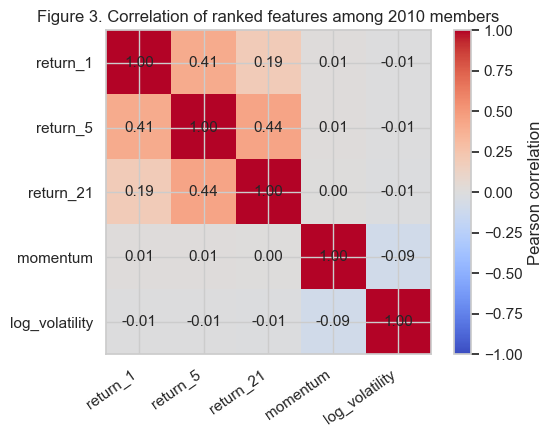

The matrix identifies redundancy between return horizons. We retain only five interpretable signals rather than adding many correlated smoothing and sector variants. Neutral filling preserves prediction coverage when a long history is unavailable.

In [31]:
features, feature_coverage = build_features(clipped_returns, sigma, members)
display(feature_coverage.loc["1990":"2010"].mean().rename("Observed member coverage").to_frame())
corr_days = members.loc["2010"].index
corr_mask = members.loc[corr_days].to_numpy()
feature_sample = pd.DataFrame({name: values.loc[corr_days].to_numpy()[corr_mask]
                                 for name, values in features.items()})
fig, ax = plt.subplots(figsize=(6, 4.5))
feature_corr = feature_sample.corr()
im = ax.imshow(feature_corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(5), feature_corr.columns, rotation=35, ha="right")
ax.set_yticks(range(5), feature_corr.index)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{feature_corr.iloc[i, j]:.2f}", ha="center", va="center")
fig.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Figure 3. Correlation of ranked features among 2010 members")
fig.tight_layout()
plt.show()
display(Markdown("The matrix identifies redundancy between return horizons. We retain only five interpretable "
                 "signals rather than adding many correlated smoothing and sector variants. "
                 "Neutral filling preserves prediction coverage when a long history is unavailable."))


## 3.4 Models, small grids and walk-forward fitting

Lasso minimizes \(\frac{1}{2n}\sum(y-\hat y)^2+\alpha\|w\|_1\); its penalty shrinks
coefficients and can set them to zero. The forest averages 100 regression trees, whose splits
reduce squared error; limited depth and large leaves discourage fitting noise. The MLP has
one ReLU hidden layer and a linear output, trained by Adam on squared error with an L2 weight
penalty. It can learn nonlinear relationships while remaining small enough to explain.

| Model | Tuned values | Fixed settings |
|---|---|---|
| Lasso | Alpha: 0.01, 0.001, 0.0001 | Maximum 10,000 optimizer iterations |
| Forest | Depth: 4, 8; leaf size: 1,000, 200 | 100 trees, all 5 features considered at a split |
| MLP | Hidden units: 16, 32; epochs: 20, 40 | Alpha 0.001; learning rate 0.001; batches of 1,024 |

We refit every **252 trading days**, on the latest **756 eligible trading days**, using at most
**100,000 member stock-days** per fit. Sampling and model seeds are fixed at 42. This rolling
window adapts to changing relationships without fitting the entire history. The MLP runs the
stated number of epochs, without a random validation split or automatic early stopping.
We choose the highest pooled development Sharpe within each family; exact ties favor the
simpler configuration because the grid is ordered from simpler to more complex.


In [32]:
def fit_model(spec, X, y):
    """Fit one deliberately small model; all inputs have already passed the date guard."""
    if spec["model"] == "lasso":
        model = Lasso(alpha=spec["alpha"], max_iter=10000)
        with warnings.catch_warnings():
            warnings.simplefilter("error", ConvergenceWarning)
            model.fit(X, y)
    elif spec["model"] == "forest":
        model = RandomForestRegressor(n_estimators=100, max_depth=spec["depth"],
                                      min_samples_leaf=spec["leaf"], n_jobs=-1, random_state=42)
        model.fit(X, y)
    elif spec["model"] == "mlp":
        model = MLPRegressor(hidden_layer_sizes=(spec["hidden"],), alpha=.001,
                             learning_rate_init=.001, batch_size=min(1024, len(y)),
                             early_stopping=False, random_state=42)
        for _ in range(spec["epochs"]):
            model.partial_fit(X, y)  # Exactly one epoch; no random early-stopping holdout.
    else:
        raise ValueError(f"Unknown model: {spec['model']}")
    return model


def walk_forward(features, target, membership, outcome_dates, spec, first_pred, last_pred,
                       train_start="1981-05-22", train_days=756, refit_every=252,
                       max_rows=100000, min_predictions=100):
    """Fit on past realized labels, then predict the next block of trading days."""
    days = membership.index
    prediction_days = days[(days >= pd.Timestamp(first_pred)) & (days <= pd.Timestamp(last_pred))]
    predictions = pd.DataFrame(np.nan, index=prediction_days, columns=membership.columns, dtype="float32")
    records = []
    for k in range(0, len(prediction_days), refit_every):
        date = prediction_days[k]
        eligible = days[(days >= pd.Timestamp(train_start)) & (outcome_dates < date)]
        eligible = eligible[-train_days:]  # Latest feature days whose NEXT-day labels precede this refit.
        if len(eligible) == 0:
            raise ValueError(f"No eligible training history before {date}")
        assert eligible.max() < date and outcome_dates.loc[eligible].max() < date, "lookahead"
        valid = membership.loc[eligible].to_numpy() & np.isfinite(target.loc[eligible].to_numpy())
        X = np.column_stack([v.loc[eligible].to_numpy()[valid] for v in features.values()])
        y = target.loc[eligible].to_numpy()[valid]
        if len(y) == 0:
            raise ValueError(f"No finite training targets before {date}")
        if len(y) > max_rows:
            selected = np.random.default_rng(42 + k).choice(len(y), max_rows, replace=False)
            X, y = X[selected], y[selected]
        model = fit_model(spec, X.astype("float64"), y.astype("float64"))
        block = prediction_days[k:k + refit_every]  # Predictions until the next scheduled refit.
        member_rows = membership.loc[block].to_numpy()
        X_next = np.column_stack([v.loc[block].to_numpy()[member_rows] for v in features.values()])
        block_values = np.full(member_rows.shape, np.nan, dtype="float32")
        block_values[member_rows] = model.predict(X_next.astype("float64"))
        predictions.loc[block] = block_values
        records.append({"refit": date, "last_training_feature": eligible.max(),
                        "last_training_outcome": outcome_dates.loc[eligible].max(),
                        "feature_days": len(eligible), "sampled_rows": len(y)})
    counts = np.isfinite(predictions).sum(axis=1)
    if len(counts) == 0 or (counts < min_predictions).any():
        raise ValueError(f"Fewer than {min_predictions} member predictions on a requested day")
    return predictions, pd.DataFrame(records)


## 3.5 Evaluation: what the numbers mean

We center predictions across the members known on the prediction date. This removes a
constant long bias, but does **not** guarantee zero correlation with the market.
After centering, we pair predictions with their available, unclipped next-day outcomes.

| Metric | Definition and interpretation |
|---|---|
| Daily P&L | \(R_d=\sum_i\hat r_{t,i}\tilde r_{d,i}\), where \(d\) is the trading day after \(t\); assignment equation (6) |
| Annualized Sharpe | \(\sqrt{252}\,\overline R/s_R\), sample standard deviation, benchmark zero because returns are already excess returns |
| Rank IC | Daily Spearman correlation of predictions and outcomes; its cumulative sum shows persistence in stock ordering |
| Holding period | Per-stock \(\sum_t|\hat r_{t,i}|/\sum_t|\hat r_{t,i}-\hat r_{t-1,i}|\), averaged across stocks using the **same valid consecutive pairs** in both sums |
| Market correlation | Pearson correlation of strategy P&L with next-day **raw** equal-weight returns of prediction-day members |
| Coverage | Minimum member predictions and scored predictions over **every** expected day |

A constant nonzero position has infinite holding period; an all-zero position has undefined
holding period. Missing days are never bridged. Entries, exits and transaction costs are not
priced by this approximation. Constant P&L has undefined Sharpe, and constant predictions
have undefined rank IC. Undefined values remain visible rather than becoming positive evidence.
P&L magnitudes depend on prediction scale; a separately labelled unit-volatility plot helps
compare curve shapes without changing the assignment metrics.


In [33]:
def sharpe(pnl):
    """Annualized sample Sharpe; zero variation has no defined finite Sharpe."""
    sd = pnl.std(ddof=1)
    return float(np.sqrt(252) * pnl.mean() / sd) if sd > 0 else np.nan


def holding_period(positions):
    """Equation (7) on matched consecutive valid positions, without bridging gaps."""
    paired = positions.notna() & positions.shift(1).notna()  # Adjacent trading rows only.
    numerator = positions.abs().where(paired).sum()
    denominator = positions.diff().abs().where(paired).sum()  # Change from t-1 to t.
    per_stock = (numerator / denominator).where(paired.any())
    return float(per_stock.mean()), int(np.isinf(per_stock).sum())


def score_predictions(predictions, actual, membership, raw_returns, outcome_dates,
                   start, end, min_predictions=100):
    """Score by outcome date; check every expected day before forming summary metrics."""
    expected_dates = pd.Series(membership.index, index=membership.index).shift(-1)
    if not outcome_dates.equals(expected_dates):  # Must use the next observed trading day.
        raise ValueError("Outcome dates must map to the next trading day")
    selected = outcome_dates.between(pd.Timestamp(start), pd.Timestamp(end))
    days = membership.index[selected]
    if len(days) == 0:
        raise ValueError("No realized outcomes in the requested period")
    positions = predictions.reindex(index=membership.index, columns=membership.columns).where(membership)
    positions = positions.where(np.isfinite(positions)).astype("float64")
    constant = positions.max(axis=1).eq(positions.min(axis=1))
    positions = positions.sub(positions.mean(axis=1), axis=0)  # Mean uses only prediction-day information.
    positions.loc[constant] = positions.loc[constant] * 0  # A constant forecast has exactly zero centered exposure.
    prediction_counts = positions.loc[days].notna().sum(axis=1)
    valid = positions.notna() & np.isfinite(actual)
    scored_counts = valid.loc[days].sum(axis=1)
    if (prediction_counts < min_predictions).any() or (scored_counts < min_predictions).any():
        raise ValueError(f"Fewer than {min_predictions} predictions or scored stocks on an expected day")
    positions = positions.where(valid).loc[days]
    outcomes = actual.where(valid).loc[days]
    pnl = (positions * outcomes).sum(axis=1, min_count=1)
    rp, ry = positions.rank(axis=1), outcomes.rank(axis=1)
    rp, ry = rp.sub(rp.mean(axis=1), axis=0), ry.sub(ry.mean(axis=1), axis=0)
    ic = (rp * ry).sum(axis=1) / np.sqrt((rp**2).sum(axis=1) * (ry**2).sum(axis=1))
    holding, infinite = holding_period(positions)
    market = raw_returns.shift(-1).where(membership).mean(axis=1).loc[days]  # Raw next-day returns of members at t.
    metrics = {"Sharpe": sharpe(pnl), "mean IC": ic.mean(), "holding days": holding,
               "market correlation": pnl.corr(market), "min predictions": int(prediction_counts.min()),
               "min scored": int(scored_counts.min()), "infinite holding stocks": infinite}
    pnl.index = pd.DatetimeIndex(outcome_dates.loc[days], name="outcome_date")
    ic.index = pnl.index
    return pnl, ic, metrics


In [34]:
# Visible boundary checks complement the fuller automated tests outside the notebook.
assert outcome_dates.loc["2010-12-31"] == pd.Timestamp("2011-01-03")
assert actual_outcomes.loc["2010-12-31"].equals(adjusted_returns.loc["2011-01-03"])
assert actual_outcomes.iloc[-1].isna().all()  # No outcome beyond the supplied final date.
first_prediction_day = members.index[outcome_dates.ge("1990-01-01")][0]
last_dev_prediction_day = members.index[outcome_dates.le("2010-12-31")][-1]
print("First development prediction/outcome:", first_prediction_day.date(), outcome_dates.loc[first_prediction_day].date())
print("Last development prediction/outcome:", last_dev_prediction_day.date(), outcome_dates.loc[last_dev_prediction_day].date())
print("Training cutoff example: a 2011-01-03 fit may use labels through 2010-12-31, not 2011-01-03.")


First development prediction/outcome: 1989-12-29 1990-01-02
Last development prediction/outcome: 2010-12-30 2010-12-31
Training cutoff example: a 2011-01-03 fit may use labels through 2010-12-31, not 2011-01-03.


## 3.6 Development tuning and selection
The following cell runs **11 configurations**, not the former 62-configuration study.
Four development subperiods show whether pooled performance is driven by one era; they are
diagnostics, while the predeclared selection rule remains pooled development Sharpe.
Only one line is printed per configuration. The chosen settings are shown before any test scoring.


In [35]:
model_specs = ([{"model": "lasso", "alpha": a} for a in [.01, .001, .0001]] +
            [{"model": "forest", "depth": d, "leaf": leaf} for d, leaf in product([4, 8], [1000, 200])] +
            [{"model": "mlp", "hidden": h, "epochs": e} for h, e in product([16, 32], [20, 40])])
subperiods = [("1990", "1994"), ("1995", "1999"), ("2000", "2004"), ("2005", "2010")]
development_rows, selected, best_predictions = [], {}, {}
refit_logs = []
for spec in model_specs:
    strategy_name = json.dumps(spec, sort_keys=True)
    started = time.perf_counter()
    prediction_table, records = walk_forward(features, target, members, outcome_dates,
                                            spec, first_prediction_day, last_dev_prediction_day)
    pnl, _, metrics = score_predictions(prediction_table, actual_outcomes, members, returns,
                                          outcome_dates, "1990-01-01", "2010-12-31")
    row = {"configuration": strategy_name, "study": "core tuning", **metrics}
    row.update({f"SR {a}–{b}": sharpe(pnl.loc[a:b]) for a, b in subperiods})
    development_rows.append(row)
    refit_logs.append(records)
    family = spec["model"]
    previous_best = selected.get(family, {}).get("development Sharpe", -np.inf)
    if np.isfinite(metrics["Sharpe"]) and metrics["Sharpe"] > previous_best:
        selected[family] = {"spec": dict(spec), "development Sharpe": metrics["Sharpe"]}
        best_predictions[family] = prediction_table
    print(strategy_name, "| development Sharpe", round(metrics["Sharpe"], 3),
          "| minutes", round((time.perf_counter() - started) / 60, 2), flush=True)
assert set(selected) == {"lasso", "forest", "mlp"}, "A model family has no finite development Sharpe."
display(pd.DataFrame(development_rows).round(3))
display(pd.DataFrame(selected).T.rename_axis("Selected family"))


{"alpha": 0.01, "model": "lasso"} | development Sharpe nan | minutes 0.06


/tmp/ecse551-notebook-env/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3045: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/tmp/ecse551-notebook-env/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3046: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


{"alpha": 0.001, "model": "lasso"} | development Sharpe 2.62 | minutes 0.06


{"alpha": 0.0001, "model": "lasso"} | development Sharpe 2.625 | minutes 0.06


{"depth": 4, "leaf": 1000, "model": "forest"} | development Sharpe 4.039 | minutes 0.98


...

{"epochs": 40, "hidden": 16, "model": "mlp"} | development Sharpe 3.71 | minutes 0.42


{"epochs": 20, "hidden": 32, "model": "mlp"} | development Sharpe 3.749 | minutes 0.46


{"epochs": 40, "hidden": 32, "model": "mlp"} | development Sharpe 3.963 | minutes 0.71


,configuration,study,Sharpe,mean IC,holding days,market correlation,min predictions,min scored,infinite holding stocks,SR 1990–1994,SR 1995–1999,SR 2000–2004,SR 2005–2010
0,"{""alpha"": 0.01, ""model"": ""lasso""}",core tuning,NaN,NaN,NaN,NaN,497,493,0,NaN,NaN,NaN,NaN
1,"{""alpha"": 0.001, ""model"": ""lasso""}",core tuning,2.620,0.024,1.223,0.163,497,493,0,5.199,2.925,1.346,0.981
2,"{""alpha"": 0.0001, ""model"": ""lasso""}",core tuning,2.625,0.025,1.198,0.164,497,493,0,5.274,2.924,1.335,1.038
3,"{""depth"": 4, ""leaf"": 1000, ""model"": ""forest""}",core tuning,4.039,0.028,1.120,0.145,497,493,0,7.900,4.785,2.417,1.707
4,"{""depth"": 4, ""leaf"": 200, ""model"": ""forest""}",core tuning,4.232,0.028,1.096,0.149,497,493,0,8.049,5.020,2.630,1.824
5,"{""depth"": 8, ""leaf"": 1000, ""model"": ""forest""}",core tuning,4.425,0.028,1.048,0.149,497,493,0,8.550,5.100,2.621,1.865
6,"{""depth"": 8, ""leaf"": 200, ""model"": ""forest""}",core tuning,4.749,0.028,0.974,0.150,497,493,0,8.825,5.432,2.983,2.077
7,"{""epochs"": 20, ""hidden"": 16, ""model"": ""mlp""}",core tuning,3.467,0.025,1.186,0.227,497,493,0,6.933,3.933,1.880,1.628
8,"{""epochs"": 40, ""hidden"": 16, ""model"": ""mlp""}",core tuning,3.710,0.027,1.115,0.205,497,493,0,7.275,4.283,2.153,1.715
9,"{""epochs"": 20, ""hidden"": 32, ""model"": ""mlp""}",core tuning,3.749,0.027,1.059,0.137,497,493,0,7.932,4.411,1.985,1.403


,spec,development Sharpe
Selected family,,
lasso,"{'model': 'lasso', 'alpha': 0.0001}",2.624791
forest,"{'model': 'forest', 'depth': 8, 'leaf': 200}",4.748555
mlp,"{'model': 'mlp', 'hidden': 32, 'epochs': 40}",3.963268


## 3.7 Sentiment: a small, matched exploratory comparison
Net sentiment is bullish minus bearish; activity is their sum. A flag marks a usable pair
of scores. We exclude all ambiguous duplicated permnos rather than choosing an identity
using future return availability. Sentiment dated Friday, Saturday or Sunday is averaged
into Monday's feature row; Monday's sentiment first enters Tuesday's row.

We compare return-only and return-plus-sentiment Lasso using the selected alpha, identical
training dates from July 2009 and outcomes in 2010 only. This short development comparison
does not select a test finalist and cannot establish whether sentiment works generally.


In [36]:
def align_sentiment(sentiment, trading_days):
    """Calendar-day sentiment is usable on the first trading date strictly after its date."""
    positions = trading_days.searchsorted(sentiment.index, side="right")
    keep = positions < len(trading_days)
    usable_dates = trading_days[positions[keep]]  # Fri/Sat/Sun observations all become usable on Monday.
    return sentiment.loc[keep].groupby(usable_dates).mean()


def build_sentiment_features(data_dir, membership, ambiguous_ids):
    """Three interpretable sentiment predictors; no duplicate identity is inferred from future data."""
    bull = pd.read_csv(data_dir / "psych_bullish.csv", index_col="date", parse_dates=True)
    bear = pd.read_csv(data_dir / "psych_bearish.csv", index_col="date", parse_dates=True)
    keep = [p for p in bull.columns if p in membership.columns and p not in ambiguous_ids]
    b = align_sentiment(bull[keep], membership.index).reindex_like(membership)
    r = align_sentiment(bear[keep], membership.index).reindex_like(membership)
    available = b.notna() & r.notna() & membership
    features = {"sentiment_net": rank_members(b - r, membership),
                "sentiment_activity": rank_members(b + r, membership),
                "sentiment_available": available.astype("float32")}
    return features, available.sum(axis=1) / membership.sum(axis=1), bull.index.min()


In [37]:
sentiment_features, sentiment_coverage, sentiment_start = build_sentiment_features(
    DATA_DIR, members, cleaning["ambiguous_sentiment_ids"])
display(Markdown(f"Usable sentiment covers **{sentiment_coverage.loc['2010'].mean():.1%}** of members per day in 2010. "
                 "The return features still provide predictions for stocks without sentiment."))
ablation_first_day = members.index[outcome_dates.ge("2010-01-01")][0]
ablation_sets = {"Matched returns only": features,
                    "Matched returns + sentiment": {**features, **sentiment_features}}
for strategy_name, inputs in ablation_sets.items():
    prediction_table, records = walk_forward(inputs, target, members, outcome_dates,
                                            selected["lasso"]["spec"], ablation_first_day, last_dev_prediction_day,
                                            train_start=sentiment_start + pd.Timedelta(days=1))
    pnl, _, metrics = score_predictions(prediction_table, actual_outcomes, members, returns,
                                          outcome_dates, "2010-01-01", "2010-12-31")
    development_rows.append({"configuration": strategy_name, "study": "sentiment (2010 only)", **metrics})
    refit_logs.append(records)
display(pd.DataFrame(development_rows[-2:]).round(3))
sentiment_gain = development_rows[-1]["Sharpe"] - development_rows[-2]["Sharpe"]
display(Markdown(f"Adding sentiment changes 2010 Sharpe by **{sentiment_gain:+.3f}**. "
                 "This is an exploratory difference on one development year, not evidence from an independent test."))


Usable sentiment covers **11.6%** of members per day in 2010. The return features still provide predictions for stocks without sentiment.

,configuration,study,Sharpe,mean IC,holding days,market correlation,min predictions,min scored,infinite holding stocks
0,Matched returns only,sentiment (2010 only),0.609,0.008,1.391,-0.008,499,498,0
1,Matched returns + sentiment,sentiment (2010 only),0.588,0.007,1.368,-0.006,499,498,0


Adding sentiment changes 2010 Sharpe by **-0.021**. This is an exploratory difference on one development year, not evidence from an independent test.

## 3.8 Baselines and the holding-period trade-off
The reversal rule predicts the negative mean of the last five clipped adjusted returns;
momentum predicts their sum over months 2–12. The smoothed MLP uses a fixed five-day EWMA
half-life, \(s_t=(1-a)s_{t-1}+a\hat r_t\), \(a=1-2^{-1/5}\). Smoothing is causal and trades
responsiveness for longer holdings; its half-life is not tuned on test performance.


In [38]:
baselines = {
    "5-day reversal": -clipped_returns.rolling(5, min_periods=3).mean(),  # t-4 through t.
    "12–1 momentum": clipped_returns.rolling(231, min_periods=231).sum().shift(21),  # t-251 through t-21.
}
dev_extras = {**baselines,
                 "MLP smoothed": best_predictions["mlp"].ewm(halflife=5, adjust=False).mean()}  # Past predictions through t only.
for strategy_name, prediction_table in dev_extras.items():
    pnl, _, metrics = score_predictions(prediction_table, actual_outcomes, members, returns,
                                          outcome_dates, "1990-01-01", "2010-12-31")
    row = {"configuration": strategy_name, "study": "baseline / fixed smoothing", **metrics}
    row.update({f"SR {a}–{b}": sharpe(pnl.loc[a:b]) for a, b in subperiods})
    development_rows.append(row)
development_table = pd.DataFrame(development_rows)
assert len(development_table) == 16
display(development_table.round(3))
print("16 development rows = 11 core grids + 2 matched sentiment comparisons + 2 baselines + 1 fixed smoothed variant.")


,configuration,study,Sharpe,mean IC,holding days,market correlation,min predictions,min scored,infinite holding stocks,SR 1990–1994,SR 1995–1999,SR 2000–2004,SR 2005–2010
0,"{""alpha"": 0.01, ""model"": ""lasso""}",core tuning,NaN,NaN,NaN,NaN,497,493,0,NaN,NaN,NaN,NaN
1,"{""alpha"": 0.001, ""model"": ""lasso""}",core tuning,2.620,0.024,1.223,0.163,497,493,0,5.199,2.925,1.346,0.981
2,"{""alpha"": 0.0001, ""model"": ""lasso""}",core tuning,2.625,0.025,1.198,0.164,497,493,0,5.274,2.924,1.335,1.038
3,"{""depth"": 4, ""leaf"": 1000, ""model"": ""forest""}",core tuning,4.039,0.028,1.120,0.145,497,493,0,7.900,4.785,2.417,1.707
4,"{""depth"": 4, ""leaf"": 200, ""model"": ""forest""}",core tuning,4.232,0.028,1.096,0.149,497,493,0,8.049,5.020,2.630,1.824
5,"{""depth"": 8, ""leaf"": 1000, ""model"": ""forest""}",core tuning,4.425,0.028,1.048,0.149,497,493,0,8.550,5.100,2.621,1.865
6,"{""depth"": 8, ""leaf"": 200, ""model"": ""forest""}",core tuning,4.749,0.028,0.974,0.150,497,493,0,8.825,5.432,2.983,2.077
7,"{""epochs"": 20, ""hidden"": 16, ""model"": ""mlp""}",core tuning,3.467,0.025,1.186,0.227,497,493,0,6.933,3.933,1.880,1.628
8,"{""epochs"": 40, ""hidden"": 16, ""model"": ""mlp""}",core tuning,3.710,0.027,1.115,0.205,497,493,0,7.275,4.283,2.153,1.715
9,"{""epochs"": 20, ""hidden"": 32, ""model"": ""mlp""}",core tuning,3.749,0.027,1.059,0.137,497,493,0,7.932,4.411,1.985,1.403


16 development rows = 11 core grids + 2 matched sentiment comparisons + 2 baselines + 1 fixed smoothed variant.


## 3.9 Fixed configurations evaluated on 2011–2013 outcomes
The configurations selected above are now fixed. We reproduce each selected model's development
predictions and continue the same refit schedule through 2013. The first test outcome on
3 January 2011 uses the prediction from 31 December 2010; the final observed outcome is
31 December 2013. A prediction is also produced on that final date, but it cannot be scored
without the following day's return.

We also apply each prediction one trading day late as an execution sensitivity diagnostic.
This needs no new model fitting and does not affect selection. A strategy that loses most
of its performance when delayed depends strongly on trading at the close used for its signals.


In [39]:
test_predictions, test_pnl, test_ic, test_rows = {}, {}, {}, []
for family, choice in selected.items():
    prediction_table, records = walk_forward(features, target, members, outcome_dates,
                                            choice["spec"], first_prediction_day, returns.index[-1])
    np.testing.assert_allclose(prediction_table.loc[best_predictions[family].index],
                               best_predictions[family], rtol=1e-6, atol=1e-8, equal_nan=True)
    test_predictions[family] = prediction_table
    refit_logs.append(records)
    print("Development predictions reproduced; full walk-forward complete:", family, flush=True)
test_predictions["MLP smoothed"] = test_predictions["mlp"].ewm(halflife=5, adjust=False).mean()  # Only predictions through t.
test_predictions.update(baselines)
for strategy_name, prediction_table in test_predictions.items():
    pnl, ic, metrics = score_predictions(prediction_table, actual_outcomes, members, returns,
                                             outcome_dates, "2011-01-01", "2013-12-31")
    test_pnl[strategy_name], test_ic[strategy_name] = pnl, ic
    late_predictions = prediction_table.shift(1)  # At t, use the prediction formed on the preceding trading day.
    _, _, late_metrics = score_predictions(late_predictions, actual_outcomes, members, returns,
                                           outcome_dates, "2011-01-01", "2013-12-31")
    row = {"strategy": strategy_name, **metrics, "one-day-late Sharpe": late_metrics["Sharpe"]}
    row.update({f"SR {year}": sharpe(pnl.loc[str(year)]) for year in [2011, 2012, 2013]})
    test_rows.append(row)
test_table = pd.DataFrame(test_rows).set_index("strategy")
display(test_table.round(3))
print("Test outcome days:", len(next(iter(test_pnl.values()))))


Development predictions reproduced; full walk-forward complete: lasso


Development predictions reproduced; full walk-forward complete: forest


Development predictions reproduced; full walk-forward complete: mlp


,Sharpe,mean IC,holding days,market correlation,min predictions,min scored,infinite holding stocks,one-day-late Sharpe,SR 2011,SR 2012,SR 2013
strategy,,,,,,,,,,,
lasso,1.313,0.013,0.924,0.291,498,496,0,0.852,1.219,1.662,1.157
forest,3.189,0.017,0.872,0.296,498,496,0,1.585,3.438,3.448,2.803
mlp,2.343,0.017,0.867,0.237,498,496,0,0.773,3.076,1.781,2.306
MLP smoothed,1.242,0.009,4.158,0.299,498,496,0,0.911,0.308,1.119,2.190
5-day reversal,0.728,0.008,1.604,0.177,496,496,0,0.705,1.487,-0.325,0.942
12–1 momentum,0.779,0.019,11.486,0.027,491,491,0,0.814,0.968,0.245,1.215


Test outcome days: 754


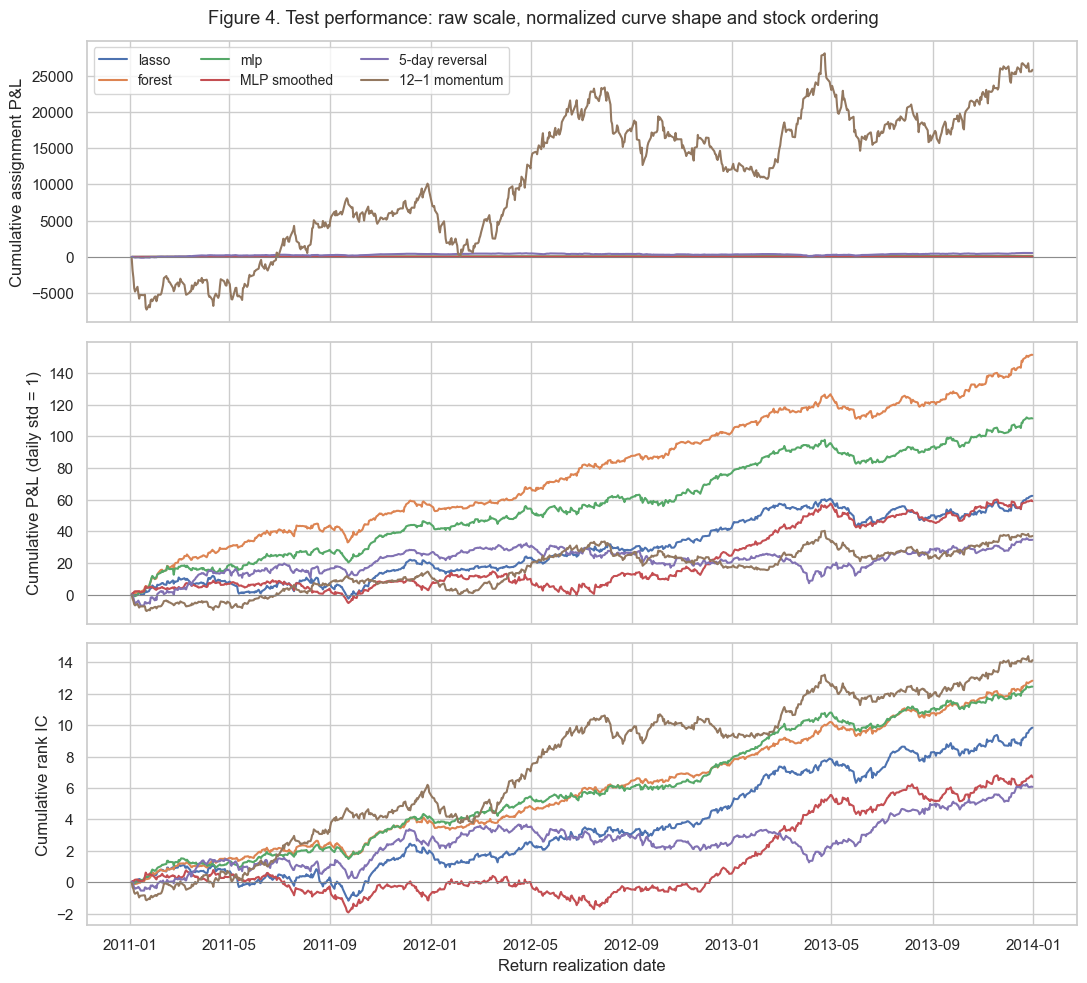

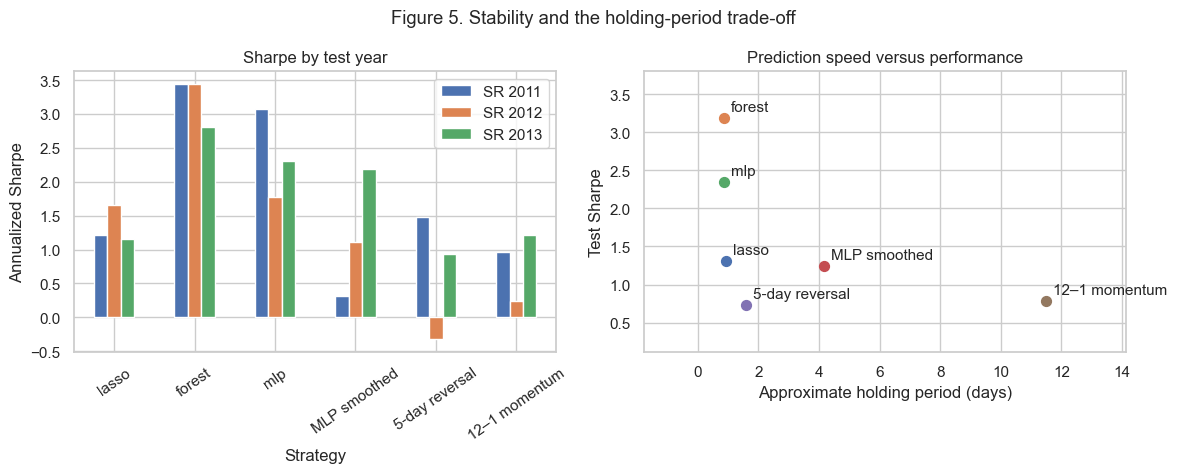

In [40]:
fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
for strategy_name in test_pnl:
    pnl = test_pnl[strategy_name]
    axes[0].plot(pnl.index, pnl.cumsum(), label=strategy_name)  # Outcomes accumulated through each displayed day.
    axes[1].plot(pnl.index, (pnl / pnl.std()).cumsum(), label=strategy_name)
    axes[2].plot(test_ic[strategy_name].index, test_ic[strategy_name].cumsum(), label=strategy_name)
for ax, label in zip(axes, ["Cumulative assignment P&L", "Cumulative P&L (daily std = 1)", "Cumulative rank IC"]):
    ax.set_ylabel(label)
    ax.axhline(0, color="grey", linewidth=.6)
axes[0].legend(ncol=3, fontsize=10)
axes[-1].set_xlabel("Return realization date")
fig.suptitle("Figure 4. Test performance: raw scale, normalized curve shape and stock ordering")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
test_table[["SR 2011", "SR 2012", "SR 2013"]].plot.bar(ax=axes[0], rot=35)
axes[0].set(title="Sharpe by test year", xlabel="Strategy", ylabel="Annualized Sharpe")
for strategy_name, row in test_table.iterrows():
    axes[1].scatter(row["holding days"], row["Sharpe"], s=50)
    axes[1].annotate(strategy_name, (row["holding days"], row["Sharpe"]), xytext=(5, 5), textcoords="offset points")
axes[1].set(title="Prediction speed versus performance", xlabel="Approximate holding period (days)", ylabel="Test Sharpe")
axes[1].margins(.25)
fig.suptitle("Figure 5. Stability and the holding-period trade-off")
fig.tight_layout()
plt.show()


## 3.10 Results, conclusion and limitations
The following interpretation is generated from this run, so it cannot silently retain results
from the former study. Sharpe measures the reward-to-variability ratio of the assignment P&L;
rank IC checks stock ordering; yearly results reveal instability hidden by a pooled number.
Market correlation and holding period address exposure and turnover, rather than prediction
accuracy alone. Positive gross metrics do not establish a profitable implementable strategy.


In [41]:
fitted_models = test_table.loc[["lasso", "forest", "mlp"]]
winner = fitted_models.Sharpe.idxmax()
best = fitted_models.loc[winner]
best_baseline_sharpe = test_table.loc[list(baselines), "Sharpe"].max()
mlp_row = test_table.loc["mlp"]
smoothed_row = test_table.loc["MLP smoothed"]
display(Markdown(
    f"The highest test Sharpe among the three fitted models is **{winner}: {best['Sharpe']:.2f}**, "
    f"compared with **{best_baseline_sharpe:.2f}** for the stronger baseline. Its mean daily rank IC is "
    f"**{best['mean IC']:.4f}**, and its yearly Sharpes range from "
    f"**{best[['SR 2011', 'SR 2012', 'SR 2013']].min():.2f}** to "
    f"**{best[['SR 2011', 'SR 2012', 'SR 2013']].max():.2f}**. "
    f"This describes the observed comparison; the test ranking is not used to choose a new configuration.\n\n"
    f"Smoothing changes MLP holding period from **{mlp_row['holding days']:.2f}** to "
    f"**{smoothed_row['holding days']:.2f} days**, while Sharpe changes from "
    f"**{mlp_row['Sharpe']:.2f}** to **{smoothed_row['Sharpe']:.2f}**. "
    f"The strongest fitted model's raw-market correlation is **{best['market correlation']:.2f}**; "
    f"daily demeaning therefore must not be confused with market neutrality. "
    f"Delaying its predictions by one day gives Sharpe **{best['one-day-late Sharpe']:.2f}**.\n\n"
    "The assignment suggests that short, roughly one-day holdings need gross Sharpe around 2 or higher "
    "to be interesting after costs; these are rough indicators, not a cost model. Three test years, "
    "correlated stock observations, changing market regimes, omitted trading costs and previously viewed "
    "test results limit the strength of our conclusions. Sentiment is particularly uncertain because "
    "its matched comparison covers only one development year.\n\n"
    "Useful improvements would be a genuinely later test period, an execution-lagged training target, "
    "explicit turnover costs and a longer sentiment history. We would fix those choices before viewing "
    "new evaluation results rather than expand this grid in response to the present test."))
all_refits = pd.concat(refit_logs, ignore_index=True)
assert (all_refits.last_training_outcome < all_refits.refit).all()
assert (test_table["min predictions"] >= 100).all() and (test_table["min scored"] >= 100).all()
print("Checked refits:", len(all_refits), "| Minimum test scored coverage:", test_table["min scored"].min())
print("Task 3 runtime (minutes):", round((time.perf_counter() - START_TIME) / 60, 1))


The highest test Sharpe among the three fitted models is **forest: 3.19**, compared with **0.78** for the stronger baseline. Its mean daily rank IC is **0.0170**, and its yearly Sharpes range from **2.80** to **3.45**. This describes the observed comparison; the test ranking is not used to choose a new configuration.

Smoothing changes MLP holding period from **0.87** to **4.16 days**, while Sharpe changes from **2.34** to **1.24**. The strongest fitted model's raw-market correlation is **0.30**; daily demeaning therefore must not be confused with market neutrality. Delaying its predictions by one day gives Sharpe **1.58**.

The assignment suggests that short, roughly one-day holdings need gross Sharpe around 2 or higher to be interesting after costs; these are rough indicators, not a cost model. Three test years, correlated stock observations, changing market regimes, omitted trading costs and previously viewed test results limit the strength of our conclusions. Sentiment is particularly uncertain because its matched comparison covers only one development year.

Useful improvements would be a genuinely later test period, an execution-lagged training target, explicit turnover costs and a longer sentiment history. We would fix those choices before viewing new evaluation results rather than expand this grid in response to the present test.

Checked refits: 319 | Minimum test scored coverage: 491
Task 3 runtime (minutes): 8.2


## Appendix — LLM usage, provenance and rubric checklist

We previously used Claude interactively and Claude Code for the larger Task 3 study. We used
ChatGPT/Codex to audit the assignment and grading grid, plan this smaller study, integrate the
notebook, generate the revised Task 3 code and explanations, and run verification. Its context
included the PDFs, supplied CSVs, current repository code and earlier study records. Those earlier
results were already known; this notebook makes no claim of a fresh blind test. Automated checks
verify specific properties, not the absence of every possible error. We remain responsible for
understanding, checking and presenting the submitted work.

Actual instructions shaping this revision included:
> “You only need to look at task 3.”
>
> “the notebook is as simple concise and structured as possible. the goal is explainability,
> I need to understand the code and be able to present it”
>
> “the notebook should combine task 1, task 2 and task 3 so if some code exists for task 1 and 2
> include it but do not touch it”

The approved implementation brief specified five return features, the three small grids above,
strict label-date checks, 2011–2013 outcome dates, at least 100 predictions daily, all assignment
metrics, a matched sentiment comparison and a one-day execution-delay diagnostic. We did not ask
the agent to maximize the observed test score. Task 1/2 calculations and settings are copied from
the existing main branch; only local imports and notebook path setup are mechanically replaced.
Their correctness was outside this Task 3 revision.

| Task 3 report criterion | Notebook evidence |
|---|---|
| Problem formulation (2) | 3.1: data, stocks, target, time periods; 3.5: objectives and metrics |
| Data analysis (2) | 3.2–3.3: statistics, distributions, volatility and correlation plots with interpretation |
| Data processing (2) | 3.2–3.3: cleaning, alignment, features and timing; 3.4–3.5: fit and evaluation guards |
| Algorithm formulation (4) | 3.4: losses, models, fixed settings, grids and walk-forward; 3.6: chosen settings |
| Algorithm rationale (4) | 3.2–3.4: tails, noise, regularization, ranks and rolling windows; 3.8: smoothing |
| Metric explanation (2) | 3.5: formulas, parameters, assumptions and edge cases |
| Performance analysis (3) | 3.6–3.10: development and test tables, yearly stability, curves and diagnostics |
| Conclusion (1) | 3.10: findings, limitations and improvements |
| Coding: loading/preprocessing (1.5) | Executable 3.2–3.3 and 3.7 |
| Coding: algorithms/data processing (3) | Executable 3.4 and 3.6–3.9 |
| Coding: evaluation (1.5) | Executable 3.5 and 3.8–3.10 |

**Submission note:** this notebook contains the Task 3 report material as requested. The assignment
PDF also lists a separate PDF report; the notebook does not itself waive that requirement.
